# 7장. 그래프로 데이터의 이야기를 보여주기

이 노트북의 목표는 그래프를 많이 만드는 것이 아닙니다. **분석 질문에 맞는 그래프를 선택하고, 그래프에 들어간 데이터 범위와 수치를 검증하며, 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분하는 것**이 핵심입니다.

금액성 그래프는 기본적으로 `order_status == "completed"` 범위를 사용합니다. `line_total`은 주문 상세 한 행의 `quantity × unit_price`이며 회계상 순매출로 단정하지 않습니다.

## 제출 정보 (Chapter 07 제출 답안)

- 이름: 장태진
- GitHub ID: Taejin-AI
- 개인 저장소: `llm-data-analysis-study`
- 사용한 LLM: Claude (Anthropic)
- 실행 환경: Windows 10, 강사 저장소 clone(`llm-data-analysis-course`), 프로젝트 `.venv` 커널. Python·pandas 버전, 저장소 HEAD, 강사 저장소 최신 커밋(`6105f42`)과 Chapter 07 관련 파일이 같은지는 아래 경로 설정 셀 Output에 있습니다.
- 최종 Notebook URL:

```text
https://github.com/Taejin-AI/llm-data-analysis-study/blob/master/chapter07/chapter07.ipynb
```

> 작성 방식: 공식 Notebook `notebooks/ch07_visualization.ipynb`의 셀을 순서대로 그대로 두고 실행했습니다. 실습 가이드 STEP의 Evidence와 답안 양식 항목은 `[추가 검증]` 코드 셀과 Markdown 셀로 사이에 넣었습니다. 공식 셀 중 수정한 것은 두 개이며 셀 안에 `[수정]`으로 표시했습니다. 경로 설정 셀(개인 저장소에서 실행해도 강사 저장소 루트를 찾도록)과 데이터 준비 셀(공식 함수가 멈추는 이유를 남기고 Chapter 06과 같은 기준 데이터로 다시 준비하도록)입니다.

## 분석 범위와 용어

- 입력: Chapter 05 결과 `data/processed/*_clean.csv` 4개. Chapter 06 제출 때 기록한 MD5와 같은 파일인지 아래에서 확인합니다.
- 분석 기간: 주문일 2025-07-01 ~ 2026-08-30 (Chapter 05·06에서 정한 유효 범위). 주문일 결측 3건(72, 143, 214)과 미래 날짜 주문 2건(256: 2027-01-15, 287: 2028-12-31)은 제외합니다.
- 금액성 그래프의 기준 데이터(이하 "기준 데이터"): `order_status == "completed"` 이고 분석 기간 안에 있는 주문 상세. Chapter 06과 같은 437행, 주문 176건, 상품 주문 금액 138,528,000입니다.
  - `orders`와 연결되지 않는 주문 상세 2행(order_id 9991·9992)은 제외하고 건수를 남깁니다.
  - 상품 마스터에 없는 상품을 참조하는 16행(4,015,000)은 버리지 않고 `(상품 정보 없음)`으로 따로 표시합니다. 그래서 카테고리별 합계와 월별 합계가 같은 범위가 됩니다.
  - 카테고리는 글자 사이 공백을 지운 값을 사용합니다(`뷰 티` → `뷰티` 등 표기 변형 3개). 지우지 않으면 막대가 8개가 아니라 11개가 됩니다.
- 상품 가격 히스토그램은 주문 상태와 무관한 상품 마스터 96개, 주문 상태 막대그래프는 전체 주문 300건을 사용합니다(공식 Notebook 기준).
- 금액 용어: `line_total = quantity × unit_price`는 상품 주문 금액입니다. 할인·쿠폰·배송비·세금·실제 결제액 정보가 없으므로 회계상 매출이라고 부르지 않습니다. 공식 함수의 제목·축 이름("완료 주문 금액")은 원문 그대로 두었습니다.
- 질문별로 필요한 테이블만 연결합니다. 카테고리·월별 그래프는 `order_items` + `orders` + `products`, 상위 고객 그래프만 `orders.customer_id`를 사용하며 `customers`는 어떤 그래프에도 필요하지 않습니다.

## 실습 가이드 STEP과 이 Notebook의 위치

| 가이드 STEP | 이 Notebook 위치 | 답안 양식 |
| --- | --- | --- |
| 0 제출용 Notebook 준비 | 공식 Notebook 복사본, `[수정]` 경로 셀 | 제출 정보 |
| 1 시각화 질문 정의 | 1번 공식 질문표 + `[추가 검증] STEP 1` | 1 |
| 2 집계표 먼저 확인 | `[추가 검증]` 기준 데이터·검증표, 공식 집계표 셀 | 2~4 원본 집계값 |
| 3 막대그래프 | 3번 + `[추가 검증]` 그래프 1 교차 검증 | 2 |
| 4 선그래프 | 4번 + `[추가 검증]` 그래프 2 교차 검증·분해 | 3 |
| 5 분포 그래프 | 5·6번 + `[추가 검증]` bins 비교·극단값 확인 | 4 |
| 6 그래프와 수치 교차 검증 | 그래프마다 `[추가 검증]` + 9번 종합표 | 5 |
| 7 오해를 줄이는 그래프 점검 | 9번 `[추가 검증]` 점검표 | 5 |
| 8 스크립트 재실행 | 10번 + `[추가 검증] STEP 8` | 5 한계 |
| 9 최종 시각화 해석 | 11번 뒤 답안 6 | 6 |

## 0. 사용 방법

- 위에서부터 차례대로 실행합니다.
- 입력은 Chapter 05에서 만든 `data/processed/*_clean.csv`입니다.
- 파일이 없다면 프로젝트 루트에서 `python scripts/preprocess_data.py`를 먼저 실행합니다.
- 그래프를 보기 전에 **시각화용 집계 검증표**를 먼저 확인합니다.
- 대표 그래프마다 `관찰 → 해석 → 한계 → 다음 질문`을 Markdown 셀에 직접 작성합니다.
- 실제 실행 결과 숫자를 보고 작성하며 강의안의 예시를 정답처럼 사용하지 않습니다.

## 1. 질문에 맞는 그래프를 먼저 고릅니다

| 분석 질문 | 그래프 | 데이터 범위 |
| --- | --- | --- |
| 카테고리별 완료 주문 금액은 어떻게 다른가? | 막대그래프 | completed 주문 상세 |
| 월별 완료 주문 금액은 어떻게 변하는가? | 선그래프 | completed + 유효한 주문일 |
| 상품 가격은 어느 구간에 몰려 있는가? | 히스토그램 | 전체 상품 마스터 |
| 상품 가격과 완료 주문 판매 수량은 어떤 패턴인가? | 산점도 | completed 상품 집계 |
| 완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가? | 가로 막대그래프 | completed 고객 집계 |
| 주문 상태별 주문 수는 어떻게 다른가? | 막대그래프 | 전체 orders |

> 그래프 종류보다 먼저 **질문과 데이터 범위**를 고정합니다.

### STEP 1. 내가 정한 시각화 질문

공식 질문표(위 셀)를 출발점으로 두고, 질문마다 그래프 종류·선택 이유·데이터 범위·필요한 테이블을 먼저 정했습니다. 그래프를 그린 뒤에 질문을 붙이지 않기 위해서입니다.

In [1]:
# [추가 검증] STEP 1. 시각화 질문 → 그래프 → 선택 이유 → 범위 → 필요한 테이블
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

my_viz_questions = pd.DataFrame([
    {"id": "V1", "question": "카테고리별 completed 상품 주문 금액은 얼마나 다른가? 1위와 7위의 차이는 몇 배인가?",
     "graph": "세로 막대그래프(금액 내림차순)", "reason": "범주 간 크기 비교. 값 축이 0에서 시작해야 배수 비교가 왜곡되지 않음",
     "scope": "completed + 2025-07-01~2026-08-30", "tables": "order_items + orders(order_status, order_date) + products(category)"},
    {"id": "V2", "question": "월별 completed 상품 주문 금액은 어떻게 변했고, 변화는 주문 수와 주문당 금액 중 무엇과 함께 움직였는가?",
     "graph": "선그래프 + 보조 패널(주문 수, 주문당 금액)", "reason": "시간 순서가 핵심. 금액 하나만 보면 주문 수 감소와 객단가 변화를 구분할 수 없음",
     "scope": "completed + 2025-07-01~2026-08-30, 14개월", "tables": "order_items + orders(order_date, order_status)"},
    {"id": "V3", "question": "상품 가격은 어느 구간에 몰려 있고, 극단값은 오류인가 실제 값인가?",
     "graph": "히스토그램(bins 10/20/30 비교)", "reason": "숫자형 분포 확인. bins와 극단값 1개가 그래프 인상을 바꾸는지 확인",
     "scope": "상품 마스터 96개 (주문 상태 무관)", "tables": "products(price) + order_items(unit_price)로 극단값 대조"},
    {"id": "V4", "question": "상품 가격과 completed 판매 수량 사이에 패턴이 있는가?",
     "graph": "산점도", "reason": "두 숫자형 변수의 관계. 관계가 있어도 인과로 읽지 않음",
     "scope": "completed + 분석 기간, 상품 단위 집계", "tables": "order_items + orders + products(price)"},
    {"id": "V5", "question": "completed 구매 금액 상위 고객은 반복 구매 때문인가, 큰 주문 한 건 때문인가?",
     "graph": "익명 가로 막대그래프 + 주문별 분해표", "reason": "상위 N 비교. 이름·ID 대신 순위 라벨. 금액만으로 충성도를 말하지 않음",
     "scope": "completed + 분석 기간, 고객 단위 집계", "tables": "order_items + orders(customer_id). customers 불필요"},
])
display(my_viz_questions)
print("질문 수:", len(my_viz_questions))

,id,question,graph,reason,scope,tables
0,V1,카테고리별 completed 상품 주문 금액은 얼마나 다른가? 1위와 7위의 차이는 몇 배인가?,세로 막대그래프(금액 내림차순),범주 간 크기 비교. 값 축이 0에서 시작해야 배수 비교가 왜곡되지 않음,completed + 2025-07-01~2026-08-30,"order_items + orders(order_status, order_date) + products(category)"
1,V2,"월별 completed 상품 주문 금액은 어떻게 변했고, 변화는 주문 수와 주문당 금액 중 무엇과 함께 움직였는가?","선그래프 + 보조 패널(주문 수, 주문당 금액)",시간 순서가 핵심. 금액 하나만 보면 주문 수 감소와 객단가 변화를 구분할 수 없음,"completed + 2025-07-01~2026-08-30, 14개월","order_items + orders(order_date, order_status)"
2,V3,"상품 가격은 어느 구간에 몰려 있고, 극단값은 오류인가 실제 값인가?",히스토그램(bins 10/20/30 비교),숫자형 분포 확인. bins와 극단값 1개가 그래프 인상을 바꾸는지 확인,상품 마스터 96개 (주문 상태 무관),products(price) + order_items(unit_price)로 극단값 대조
3,V4,상품 가격과 completed 판매 수량 사이에 패턴이 있는가?,산점도,두 숫자형 변수의 관계. 관계가 있어도 인과로 읽지 않음,"completed + 분석 기간, 상품 단위 집계",order_items + orders + products(price)
4,V5,"completed 구매 금액 상위 고객은 반복 구매 때문인가, 큰 주문 한 건 때문인가?",익명 가로 막대그래프 + 주문별 분해표,상위 N 비교. 이름·ID 대신 순위 라벨. 금액만으로 충성도를 말하지 않음,"completed + 분석 기간, 고객 단위 집계",order_items + orders(customer_id). customers 불필요


질문 수: 5


In [2]:
# [수정] 개인 저장소(llm-data-analysis-study/chapter07)에서 실행해도 강사 저장소 루트를 찾도록 경로 탐색만 바꿨습니다.
# 공식 셀의 변수 이름(PROJECT_ROOT, PROCESSED_DIR, REPORT_DIR, FIGURE_DIR)은 그대로 둡니다.
from pathlib import Path
import hashlib
import os
import shutil
import subprocess
import sys

import numpy as np
import pandas as pd


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        for root in (candidate, candidate / "llm-data-analysis-course"):
            if (root / "requirements.txt").exists() and (root / "scripts").exists() and (root / "src").exists():
                return root
    raise FileNotFoundError("프로젝트 루트 폴더를 찾을 수 없습니다.")


CURRENT_DIR = Path.cwd()
PROJECT_ROOT = find_project_root(CURRENT_DIR)
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"
# 제출용 이미지 폴더: 개인 저장소 chapter07/images (강사 저장소 안에서 실행하면 reports/figures)
IMAGE_DIR = CURRENT_DIR / "images" if CURRENT_DIR.name == "chapter07" else FIGURE_DIR

REPORT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

git = lambda *args: subprocess.run(["git", *args], cwd=PROJECT_ROOT, capture_output=True, text=True, encoding="utf-8").stdout.strip()
INSTRUCTOR_HEAD = "6105f42"
ch07_files = ["notebooks/ch07_visualization.ipynb", "src/visualization.py", "src/eda.py", "scripts/run_visualization.py",
              "practice/chapter07", "data/processed/customers_clean.csv", "data/processed/products_clean.csv",
              "data/processed/orders_clean.csv", "data/processed/order_items_clean.csv"]
has_instructor_commit = git("cat-file", "-t", INSTRUCTOR_HEAD) == "commit"
diff_vs_instructor = git("diff", "--stat", INSTRUCTOR_HEAD, "HEAD", "--", *ch07_files) if has_instructor_commit else "(커밋 객체 없음)"

print("Python 실행 파일:", sys.executable)
print("Python:", sys.version.split()[0], "/ pandas:", pd.__version__, "/ numpy:", np.__version__)
print("저장소 clone:", git("remote", "get-url", "origin"), "| HEAD", git("log", "-1", "--format=%h %ci"))
print(f"강사 저장소 main {INSTRUCTOR_HEAD}와 Chapter 07 관련 파일 차이:", diff_vs_instructor or "없음 (동일)")
print("현재 실행 위치:", CURRENT_DIR)
print("프로젝트 루트:", PROJECT_ROOT)
print("전처리 데이터 폴더:", PROCESSED_DIR)
print("그래프 저장 폴더:", FIGURE_DIR)
print("제출 이미지 폴더:", IMAGE_DIR)

Python 실행 파일: C:\dev\llm-data-analysis-course\.venv\Scripts\python.exe
Python: 3.14.2 / pandas: 3.0.5 / numpy: 2.5.3


저장소 clone: https://github.com/Taejin-AI/llm-data-analysis-course.git | HEAD 59b7534 2026-10-08 09:50:17 +0900
강사 저장소 main 6105f42와 Chapter 07 관련 파일 차이: 없음 (동일)
현재 실행 위치: C:\dev\llm-data-analysis-study\chapter07
프로젝트 루트: C:\dev\llm-data-analysis-course
전처리 데이터 폴더: C:\dev\llm-data-analysis-course\data\processed
그래프 저장 폴더: C:\dev\llm-data-analysis-course\reports\figures
제출 이미지 폴더: C:\dev\llm-data-analysis-study\chapter07\images


## 2. 검증된 시각화용 데이터를 준비합니다

공통 모듈은 그래프를 그리기 전에 다음을 검사합니다.

- 필수 컬럼
- PK 결측·중복
- `many_to_one` 병합
- 주문/상품 미매칭
- 숫자형 변환 실패
- `completed` 주문 범위
- 카테고리·상품·고객·월별 집계 총합

문제가 있으면 그래프를 만들기 전에 중단합니다.

In [3]:
# [수정] 공식 prepare_visualization_data()를 먼저 그대로 호출하고, 멈추면 그 이유를 기록합니다.
# 그래프에 쓸 집계표(viz_data)는 아래 [추가 검증] 셀에서 Chapter 06과 같은 기준으로 다시 만듭니다.
from src.visualization import (
    prepare_visualization_data,
    setup_korean_font,
)

selected_font = setup_korean_font()
print("사용 한글 폰트:", selected_font or "자동 선택 실패 — 설치된 한글 폰트 확인 필요")

official_error = None
try:
    viz_data = prepare_visualization_data(PROCESSED_DIR)
    print("공식 검증 통과. 완료 주문 상세 행:", len(viz_data["completed_order_sales"]))
except ValueError as error:
    official_error = str(error)
    viz_data = None
    print("공식 prepare_visualization_data() 중단:", official_error)

사용 한글 폰트: Malgun Gothic
공식 prepare_visualization_data() 중단: 주문 정보와 연결되지 않은 주문 상세가 있습니다: 2행


### 공식 함수가 멈춘 이유와 대응

공식 모듈은 "문제가 있으면 그래프를 만들기 전에 중단"하도록 만들어져 있고, 실제로 `orders`와 연결되지 않은 주문 상세 2행(order_id 9991·9992)에서 멈췄습니다. 이 2행을 빼도 상품 마스터에 없는 상품을 참조하는 completed 상세 16행에서 다시 멈추게 되어 있습니다(모듈 코드의 두 번째 `raise`).

중단 자체는 올바른 동작입니다. 다만 Chapter 05·06에서 이미 이 행들을 확인했고(Chapter 06 기준 데이터), 지우는 대신 건수를 남기고 따로 표시하기로 했으므로, 아래에서 같은 기준으로 시각화용 데이터를 다시 만듭니다. 공식 모듈의 검증 항목(필수 컬럼, PK 결측·중복, `many_to_one` 병합, 미매칭, 숫자형 변환 실패, completed 범위, 집계 총합)은 모두 같은 방식으로 수행하고 `passed`로 남깁니다. 그래프 함수(`plot_*`)와 전체 재생성 함수(`create_all_figures`)는 공식 모듈 것을 그대로 사용합니다.

In [4]:
# [추가 검증] STEP 2-1. 전처리 데이터가 Chapter 05·06 결과와 같은 파일인지 확인 (Chapter 06 제출 Notebook에 기록한 MD5와 비교)
CH06_MD5 = {
    "customers": "3fbb57a59e99b53ced41e84623aa8d19",
    "products": "57078017a0cb356794419d5ca8556888",
    "orders": "8008b763340ed8ef3df48f8e0c746cf4",
    "order_items": "bb3f3fa8216b38e2c40729ae3dc5b658",
}
md5 = lambda p: hashlib.md5(Path(p).read_bytes()).hexdigest()
raw = {}
file_rows = []
for name, expected in CH06_MD5.items():
    path = PROCESSED_DIR / f"{name}_clean.csv"
    raw[name] = pd.read_csv(path)
    file_rows.append({"file": path.name, "bytes": path.stat().st_size, "shape": raw[name].shape,
                      "md5_same_as_ch06": md5(path) == expected})
file_check = pd.DataFrame(file_rows)
display(file_check)
print("강사 저장소에 커밋된 Chapter 05 결과 대비 변경:", git("status", "--short", "--", "data/processed") or "없음")
assert file_check["md5_same_as_ch06"].all()

,file,bytes,shape,md5_same_as_ch06
0,customers_clean.csv,5924,"(150, 6)",True
1,products_clean.csv,3971,"(96, 4)",True
2,orders_clean.csv,16421,"(300, 7)",True
3,order_items_clean.csv,24671,"(752, 6)",True


강사 저장소에 커밋된 Chapter 05 결과 대비 변경: 없음


In [5]:
# [추가 검증] STEP 2-2. 기준 데이터(completed + 분석 기간) 구성과 시각화용 집계표 생성
# 공식 prepare_visualization_data()와 같은 검증을 거치되, 미매칭 행은 지우지 않고 건수를 남긴 뒤 범위에서 제외/표시합니다.
VALID_START, VALID_END = pd.Timestamp("2025-07-01"), pd.Timestamp("2026-08-30")

customers = raw["customers"].copy()
products = raw["products"].copy()
orders = raw["orders"].copy()
order_items = raw["order_items"].copy()

orders["order_date"] = pd.to_datetime(orders["order_date"], errors="coerce")
products["category_raw"] = products["category"]
products["category"] = products["category"].str.replace(r"\s+", "", regex=True)   # '뷰 티' → '뷰티'
for frame, column in [(products, "price"), (order_items, "quantity"), (order_items, "unit_price"), (order_items, "line_total")]:
    frame[column] = pd.to_numeric(frame[column], errors="coerce")

# 1) 필수 컬럼 · PK · 숫자형 변환 실패
from src.visualization import REQUIRED_COLUMNS
missing_cols = {n: sorted(req - set(df.columns)) for n, df in
                {"customers": customers, "products": products, "orders": orders, "order_items": order_items}.items()
                for req in [REQUIRED_COLUMNS[n]]}
pk_check = {f"{n}.{k}": (int(df[k].isna().sum()), int(df[k].duplicated().sum()))
            for n, df, k in [("orders", orders, "order_id"), ("products", products, "product_id"), ("customers", customers, "customer_id")]}
numeric_fail = {"products.price": int(products["price"].isna().sum()), "order_items.quantity": int(order_items["quantity"].isna().sum()),
                "order_items.unit_price": int(order_items["unit_price"].isna().sum()), "order_items.line_total": int(order_items["line_total"].isna().sum())}
print("필수 컬럼 누락:", missing_cols)
print("PK (결측, 중복):", pk_check)
print("숫자형 변환 실패:", numeric_fail)
assert not any(missing_cols.values()) and all(v == (0, 0) for v in pk_check.values()) and not any(numeric_fail.values())
assert np.allclose(order_items["line_total"], order_items["quantity"] * order_items["unit_price"])

# 2) many_to_one 병합 + 미매칭 건수 기록
items = order_items.merge(orders[["order_id", "customer_id", "order_date", "order_status", "payment_method"]],
                          on="order_id", how="left", validate="many_to_one", indicator="_order")
items = items.merge(products[["product_id", "product_name", "category", "price"]],
                    on="product_id", how="left", validate="many_to_one", indicator="_product")
items["category"] = items["category"].fillna("(상품 정보 없음)")
items["in_period"] = items["order_date"].between(VALID_START, VALID_END)
assert len(items) == len(order_items)

base = items[(items["_order"] == "both") & (items["order_status"] == "completed") & items["in_period"]].copy()
base["customer_id"] = base["customer_id"].astype(int)
base["order_month"] = base["order_date"].dt.to_period("M")
BASE_TOTAL = float(base["line_total"].sum())

completed_all = items[(items["_order"] == "both") & (items["order_status"] == "completed")]
steps = pd.DataFrame([
    {"단계": "전처리 후 order_items 전체", "행": len(items), "주문": items["order_id"].nunique(), "금액": items["line_total"].sum()},
    {"단계": "orders와 연결 안 됨 (order_id 9991·9992) → 제외", "행": int((items["_order"] == "left_only").sum()), "주문": 2,
     "금액": items.loc[items["_order"] == "left_only", "line_total"].sum()},
    {"단계": "completed (연결된 행)", "행": len(completed_all), "주문": completed_all["order_id"].nunique(), "금액": completed_all["line_total"].sum()},
    {"단계": "completed 중 분석 기간 밖 (주문일 결측·미래) → 제외", "행": int((~completed_all["in_period"]).sum()),
     "주문": completed_all.loc[~completed_all["in_period"], "order_id"].nunique(), "금액": completed_all.loc[~completed_all["in_period"], "line_total"].sum()},
    {"단계": "completed + 분석 기간 (기준 데이터)", "행": len(base), "주문": base["order_id"].nunique(), "금액": BASE_TOTAL},
    {"단계": "  그중 상품 마스터에 없음 → '(상품 정보 없음)'으로 표시", "행": int((base["_product"] == "left_only").sum()),
     "주문": base.loc[base["_product"] == "left_only", "order_id"].nunique(), "금액": base.loc[base["_product"] == "left_only", "line_total"].sum()},
])
display(steps)
print(f"기준 데이터: {len(base)}행 / 주문 {base['order_id'].nunique()}건 / 상품 주문 금액 {BASE_TOTAL:,.0f} (Chapter 06과 동일 여부: "
      f"{len(base) == 437 and base['order_id'].nunique() == 176 and BASE_TOTAL == 138_528_000})")

# 3) 공식 집계표와 같은 컬럼 이름으로 시각화용 집계표 생성
category_sales = (base.groupby("category", as_index=False)
                  .agg(total_quantity=("quantity", "sum"), completed_amount=("line_total", "sum"),
                       completed_order_count=("order_id", "nunique"), sold_products=("product_id", "nunique"))
                  .sort_values("completed_amount", ascending=False).reset_index(drop=True))
category_sales["amount_ratio_pct"] = category_sales["completed_amount"].div(BASE_TOTAL).mul(100).round(2)
category_sales["average_unit_price"] = category_sales["completed_amount"].div(category_sales["total_quantity"]).round(0)

monthly_sales = (base.groupby("order_month", as_index=False)
                 .agg(completed_amount=("line_total", "sum"), completed_order_count=("order_id", "nunique"), item_rows=("line_total", "size"))
                 .sort_values("order_month").reset_index(drop=True))
monthly_sales["month_start"] = monthly_sales["order_month"].dt.to_timestamp()
monthly_sales["average_completed_order_amount"] = monthly_sales["completed_amount"].div(monthly_sales["completed_order_count"]).round(0)

product_sales = (base.groupby(["product_id", "product_name", "category", "price"], as_index=False, dropna=False)
                 .agg(completed_quantity=("quantity", "sum"), completed_amount=("line_total", "sum"), completed_order_count=("order_id", "nunique"))
                 .sort_values("completed_amount", ascending=False).reset_index(drop=True))

customer_sales = (base.groupby("customer_id", as_index=False)
                  .agg(completed_order_count=("order_id", "nunique"), completed_amount=("line_total", "sum"))
                  .sort_values("completed_amount", ascending=False).reset_index(drop=True))
customer_sales["average_completed_order_amount"] = customer_sales["completed_amount"].div(customer_sales["completed_order_count"]).round(0)

order_status = (orders["order_status"].fillna("missing").value_counts().rename_axis("order_status").reset_index(name="order_count"))
invalid_date_sales = completed_all[~completed_all["in_period"]].copy()
completed_order_sales = base

# 4) 집계 총합 검증 (공식 4개 + 기준 데이터끼리 비교 2개)
validation = pd.DataFrame([
    {"check": "category_completed_amount", "expected": BASE_TOTAL, "actual": float(category_sales["completed_amount"].sum())},
    {"check": "product_completed_amount", "expected": BASE_TOTAL, "actual": float(product_sales["completed_amount"].sum())},
    {"check": "customer_completed_amount", "expected": BASE_TOTAL, "actual": float(customer_sales["completed_amount"].sum())},
    {"check": "monthly_completed_amount_valid_dates", "expected": BASE_TOTAL, "actual": float(monthly_sales["completed_amount"].sum())},
    {"check": "monthly_completed_order_count", "expected": float(base["order_id"].nunique()), "actual": float(monthly_sales["completed_order_count"].sum())},
    {"check": "category_total_quantity", "expected": float(base["quantity"].sum()), "actual": float(category_sales["total_quantity"].sum())},
])
validation["difference"] = validation["actual"] - validation["expected"]
validation["passed"] = validation["difference"].abs().le(1e-6)
assert validation["passed"].all(), validation

viz_data = {
    "customers": customers, "products": products, "orders": orders, "order_items": order_items,
    "completed_order_sales": completed_order_sales, "category_sales": category_sales, "monthly_sales": monthly_sales,
    "product_sales": product_sales, "customer_sales": customer_sales, "order_status": order_status,
    "invalid_date_sales": invalid_date_sales, "visualization_validation": validation,
}
print("완료 주문 상세 행(기준 데이터):", len(completed_order_sales))
print("월별 집계에서 제외된 completed 상세(주문일 결측·미래):", len(invalid_date_sales), "행 /", f"{invalid_date_sales['line_total'].sum():,.0f}")

필수 컬럼 누락: {'customers': [], 'products': [], 'orders': [], 'order_items': []}
PK (결측, 중복): {'orders.order_id': (0, 0), 'products.product_id': (0, 0), 'customers.customer_id': (0, 0)}
숫자형 변환 실패: {'products.price': 0, 'order_items.quantity': 0, 'order_items.unit_price': 0, 'order_items.line_total': 0}


,단계,행,주문,금액
0,전처리 후 order_items 전체,752,301,252140000.0
1,orders와 연결 안 됨 (order_id 9991·9992) → 제외,2,2,922000.0
2,completed (연결된 행),446,179,141340000.0
3,completed 중 분석 기간 밖 (주문일 결측·미래) → 제외,9,3,2812000.0
4,completed + 분석 기간 (기준 데이터),437,176,138528000.0
5,그중 상품 마스터에 없음 → '(상품 정보 없음)'으로 표시,16,16,4015000.0


기준 데이터: 437행 / 주문 176건 / 상품 주문 금액 138,528,000 (Chapter 06과 동일 여부: True)
완료 주문 상세 행(기준 데이터): 437
월별 집계에서 제외된 completed 상세(주문일 결측·미래): 9 행 / 2,812,000


In [6]:
viz_data["visualization_validation"]

,check,expected,actual,difference,passed
0,category_completed_amount,138528000.0,138528000.0,0.0,True
1,product_completed_amount,138528000.0,138528000.0,0.0,True
2,customer_completed_amount,138528000.0,138528000.0,0.0,True
3,monthly_completed_amount_valid_dates,138528000.0,138528000.0,0.0,True
4,monthly_completed_order_count,176.0,176.0,0.0,True
5,category_total_quantity,1350.0,1350.0,0.0,True


### 검증 결과 기록

`passed`가 모두 `True`인지 확인한 뒤 아래 내용을 자신의 말로 작성합니다.

- 총합 검증 결과:
- 문제가 있었다면 원인:
- 시각화를 진행해도 된다고 판단한 이유:

#### 검증 결과 기록

- 총합 검증 결과: 6개 항목 모두 `passed = True`, 차이 0. 카테고리·상품·고객·월별 금액 합계가 기준 합계 138,528,000과 같고, 월별 주문 수 합(176)과 카테고리 수량 합(1,350)도 기준 데이터와 같습니다.
- 문제가 있었다면 원인: 공식 함수는 `orders`에 없는 주문 상세 2행(922,000)에서 멈췄습니다. 그 뒤에는 상품 마스터에 없는 상품을 참조하는 completed 상세 16행(4,015,000)이 있습니다. 둘 다 Chapter 05 전처리에서 관계 오류를 조용히 지우지 않고 남겨 둔 행입니다.
- 시각화를 진행해도 된다고 판단한 이유: 2행은 주문 정보(날짜·상태)가 없어 어떤 금액성 그래프에도 넣을 수 없으므로 제외하고 건수를 남겼습니다. 16행은 주문 정보가 있으므로 `(상품 정보 없음)`으로 표시해 합계에서 빠지지 않게 했습니다. 그 결과 Chapter 06과 같은 기준 데이터(437행, 176건, 138,528,000)가 되었고, 분류 기준을 바꿔도 합계가 같다는 것을 확인했습니다.

In [7]:
# [추가 검증] 그래프 값과 집계표 값을 비교하기 위한 도구.
# 공식 plot_* 함수는 Figure를 돌려주지 않고 plt.show()로 끝나므로, show()를 잠시 가로채 Figure를 잡아 축 값을 읽습니다.
import matplotlib.pyplot as plt


def capture_figure(plot_function, *args, **kwargs):
    """plot_* 함수를 실행하고 (저장 경로, Figure)를 돌려줍니다. 그래프는 화면에 표시하지 않습니다."""
    captured = {}
    original_show = plt.show
    plt.show = lambda *a, **k: captured.setdefault("fig", plt.gcf())
    try:
        saved_path = plot_function(*args, **kwargs, show=True)
    finally:
        plt.show = original_show
    return saved_path, captured["fig"]


def audit_axes(ax):
    """축 이름·단위 포맷·0 시작 여부 등 오해를 줄이는 항목을 읽습니다."""
    return {
        "title": ax.get_title(), "xlabel": ax.get_xlabel(), "ylabel": ax.get_ylabel(),
        "xlim": tuple(round(v, 2) for v in ax.get_xlim()), "ylim": tuple(round(v, 2) for v in ax.get_ylim()),
        "y_starts_at_0": bool(ax.get_ylim()[0] == 0), "x_starts_at_0": bool(ax.get_xlim()[0] == 0),
        "n_bars": len(ax.patches), "n_lines": len(ax.lines), "legend": ax.get_legend() is not None,
    }


cross_checks = []   # (그래프, 비교 항목, 그래프 값, 집계표 값, 일치)


def record_check(graph, item, graph_value, table_value, ok):
    cross_checks.append({"그래프": graph, "비교 항목": item, "그래프 값": graph_value, "집계표 값": table_value, "일치": bool(ok)})


print("도구 준비 완료")

도구 준비 완료


## 3. 카테고리별 완료 주문 금액 — 막대그래프

범주별 크기 비교이므로 막대그래프를 사용합니다. 값 축은 0에서 시작합니다. 금액이 크다는 사실만으로 선호도가 높다고 단정하지 않습니다.

In [8]:
from src.visualization import plot_category_sales

category_sales[["category", "total_quantity", "completed_amount", "amount_ratio_pct"]]

,category,total_quantity,completed_amount,amount_ratio_pct
0,패션,290.0,32940000.0,23.78
1,식품,218.0,24345000.0,17.57
2,전자기기,172.0,20445000.0,14.76
3,뷰티,178.0,17542000.0,12.66
4,도서,168.0,16895000.0,12.20
5,스포츠,165.0,13237000.0,9.56
6,생활용품,125.0,9109000.0,6.58
7,(상품 정보 없음),34.0,4015000.0,2.90


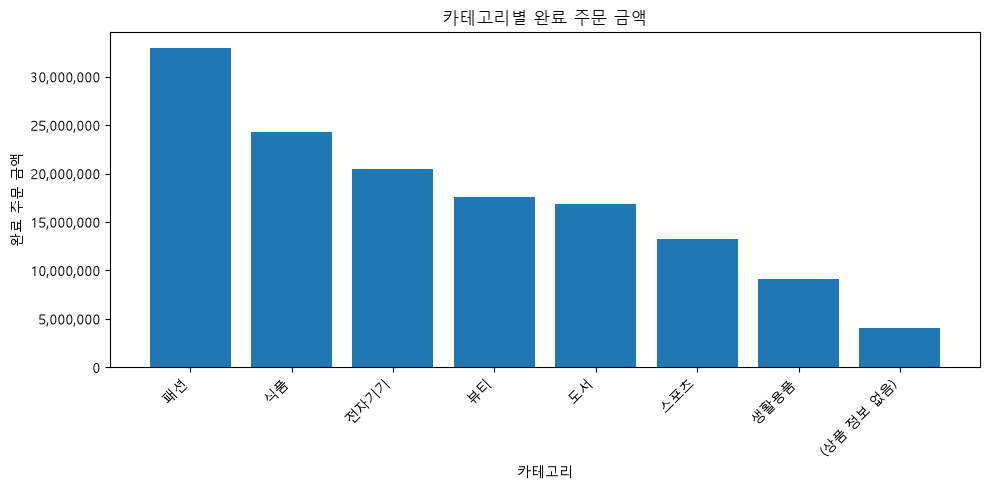

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_category_completed_amount_bar.png')

In [9]:
category_path = plot_category_sales(
    category_sales,
    FIGURE_DIR / "ch07_category_completed_amount_bar.png",
    show=True,
)
category_path

In [10]:
# [추가 검증] 그래프 1 교차 검증: 막대 높이·라벨·순서 = 집계표, 값 축 0 시작, 축 이름·단위
from src.visualization import plot_category_sales

_, fig1 = capture_figure(plot_category_sales, category_sales, IMAGE_DIR / "graph01.png")
ax1 = fig1.axes[0]
bar_heights = [patch.get_height() for patch in ax1.patches]
bar_labels = [label.get_text() for label in ax1.get_xticklabels()]
audit1 = audit_axes(ax1)
plt.close(fig1)

record_check("1 카테고리 막대", "막대 8개 높이 = completed_amount", [f"{v:,.0f}" for v in bar_heights[:3]] + ["…"],
             [f"{v:,.0f}" for v in category_sales["completed_amount"].head(3)] + ["…"],
             np.allclose(bar_heights, category_sales["completed_amount"]))
record_check("1 카테고리 막대", "x축 라벨 순서 = 집계표 순서(금액 내림차순)", bar_labels[:3] + ["…"], list(category_sales["category"].head(3)) + ["…"],
             bar_labels == list(category_sales["category"]))
record_check("1 카테고리 막대", "막대 높이 합 = 기준 합계", f"{sum(bar_heights):,.0f}", f"{BASE_TOTAL:,.0f}", np.isclose(sum(bar_heights), BASE_TOTAL))
record_check("1 카테고리 막대", "값 축 0 시작", audit1["ylim"][0], 0, audit1["y_starts_at_0"])
print("축 점검:", {k: audit1[k] for k in ["title", "xlabel", "ylabel", "y_starts_at_0", "n_bars"]})
print("y축 눈금 표기 예:", [t.get_text() for t in ax1.get_yticklabels()][:4], "(천 단위 구분 기호 = 원 단위 금액)")

top, bottom = category_sales.iloc[0], category_sales[category_sales["category"] != "(상품 정보 없음)"].iloc[-1]
print(f"\n1위 {top['category']} {top['completed_amount']:,.0f} / 실제 카테고리 최하위 {bottom['category']} {bottom['completed_amount']:,.0f}"
      f" → {top['completed_amount'] / bottom['completed_amount']:.2f}배")
print("1위 카테고리 비중:", top["amount_ratio_pct"], "% / 상위 3개 비중:", category_sales["amount_ratio_pct"].head(3).sum().round(2), "%")

# 공백을 지우지 않았을 때의 라벨 수 (시각화 위험 확인용)
raw_labels = (base.merge(products[["product_id", "category_raw"]], on="product_id", how="left")["category_raw"]
              .fillna("(상품 정보 없음)").value_counts())
variant_labels = [k for k in raw_labels.index if " " in k and k != "(상품 정보 없음)"]
print(f"\n카테고리 공백을 정리하지 않으면 막대 수: {len(raw_labels)}개 (정리 후 {len(category_sales)}개). 표기 변형 라벨 {len(variant_labels)}개:", variant_labels,
      "/ 해당 행:", int(raw_labels[variant_labels].sum()))
display(category_sales[["category", "completed_amount", "amount_ratio_pct", "total_quantity", "average_unit_price", "completed_order_count", "sold_products"]])

축 점검: {'title': '카테고리별 완료 주문 금액', 'xlabel': '카테고리', 'ylabel': '완료 주문 금액', 'y_starts_at_0': True, 'n_bars': 8}
y축 눈금 표기 예: ['0', '5,000,000', '10,000,000', '15,000,000'] (천 단위 구분 기호 = 원 단위 금액)

1위 패션 32,940,000 / 실제 카테고리 최하위 생활용품 9,109,000 → 3.62배
1위 카테고리 비중: 23.78 % / 상위 3개 비중: 56.11 %

카테고리 공백을 정리하지 않으면 막대 수: 11개 (정리 후 8개). 표기 변형 라벨 3개: ['생활 용품', '뷰 티', '전자 기기'] / 해당 행: 11


,category,completed_amount,amount_ratio_pct,total_quantity,average_unit_price,completed_order_count,sold_products
0,패션,32940000.0,23.78,290.0,113586.0,68,15
1,식품,24345000.0,17.57,218.0,111674.0,60,16
2,전자기기,20445000.0,14.76,172.0,118866.0,53,14
3,뷰티,17542000.0,12.66,178.0,98551.0,54,17
4,도서,16895000.0,12.20,168.0,100565.0,47,13
5,스포츠,13237000.0,9.56,165.0,80224.0,47,10
6,생활용품,9109000.0,6.58,125.0,72872.0,42,10
7,(상품 정보 없음),4015000.0,2.90,34.0,118088.0,16,5


### 그래프 1 기록

- **관찰:** 실제 그래프와 집계표에서 직접 확인한 사실
- **해석:** 이 차이가 의미할 수 있는 내용
- **한계:** 금액만으로 알 수 없는 것
- **다음 질문:** 판매 수량·단가·상품 수 중 무엇을 더 확인할 것인가?

#### 그래프 1 기록 (대표 그래프 1)

- **관찰:** 막대 8개의 높이는 집계표 `completed_amount`와 모두 일치하고 합계는 138,528,000입니다. 패션 32,940,000(23.78%)이 1위이고 식품 24,345,000(17.57%), 전자기기 20,445,000(14.76%)이 뒤를 잇습니다. 실제 카테고리 중 최하위 생활용품은 9,109,000(6.58%)으로 패션의 약 3.6분의 1입니다. `(상품 정보 없음)` 막대 4,015,000(2.90%)이 맨 오른쪽에 있습니다. 상위 3개 카테고리가 56.1%를 차지합니다.
- **해석:** 패션이 1위인 것은 평균 판매 단가(113,586, 7개 중 3위)보다 판매 수량(290, 1위)이 많기 때문입니다. 전자기기는 평균 단가(118,866)가 가장 높지만 수량(172)이 적어 3위입니다. 금액 막대만 보면 "패션이 비싸게 팔린다"로 읽힐 수 있는데, 수량 열을 같이 보면 그렇지 않습니다.
- **한계:** 금액은 할인·반품 전 상품 주문 금액입니다. 카테고리별 상품 수(10~17개)가 다르므로 카테고리 총액은 상품 구색 크기의 영향도 받습니다. `(상품 정보 없음)` 16행은 어느 카테고리인지 알 수 없어 실제 순위가 조금 달라질 수 있습니다(최대 4,015,000이 한 카테고리에 더해지는 경우 스포츠 13,237,000이 뷰티·도서를 넘을 수는 있으나 상위 3개 순서는 바뀌지 않습니다).
- **다음 질문:** 패션의 수량 290이 특정 상품(패션 상품 096, 수량 70) 한 개에 몰려 있는지, 카테고리별 주문당 수량은 어떻게 다른지 확인해야 합니다.

## 4. 월별 완료 주문 금액 — 선그래프

시간 순서가 핵심인 질문이므로 선그래프를 사용합니다. 첫 달과 마지막 달이 완전한 한 달인지, 중간 월이 비어 있다면 실제 0인지 데이터 누락인지 확인합니다.

In [11]:
from src.visualization import plot_monthly_sales

monthly_sales[
    [
        "order_month",
        "completed_amount",
        "completed_order_count",
        "average_completed_order_amount",
    ]
]

,order_month,completed_amount,completed_order_count,average_completed_order_amount
0,2025-07,9561000.0,11,869182.0
1,2025-08,9362000.0,17,550706.0
2,2025-09,5299000.0,4,1324750.0
3,2025-10,12629000.0,17,742882.0
4,2025-11,9583000.0,16,598938.0
5,2025-12,8581000.0,12,715083.0
6,2026-01,8135000.0,9,903889.0
7,2026-02,7689000.0,12,640750.0
8,2026-03,7247000.0,13,557462.0
9,2026-04,11459000.0,14,818500.0


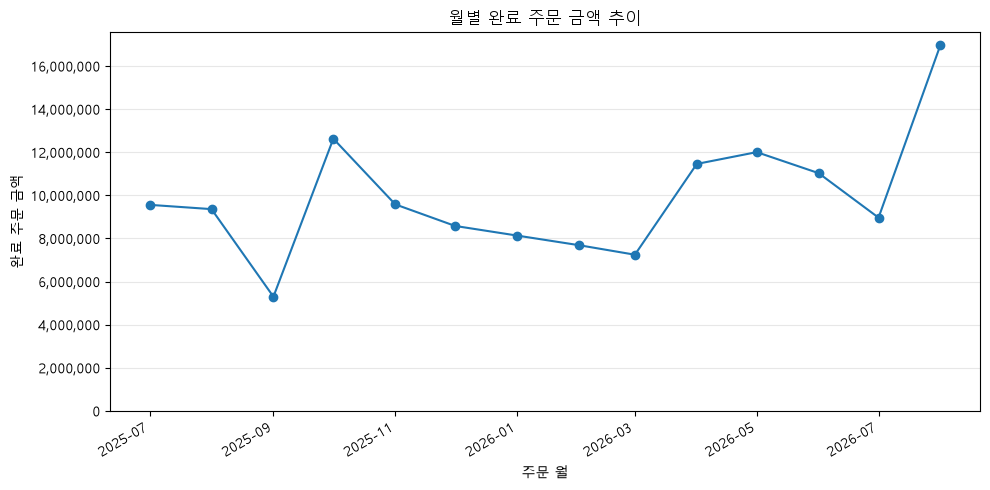

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_monthly_completed_amount_line.png')

In [12]:
monthly_path = plot_monthly_sales(
    monthly_sales,
    FIGURE_DIR / "ch07_monthly_completed_amount_line.png",
    show=True,
)
monthly_path

축 점검: {'title': '월별 완료 주문 금액 추이', 'xlabel': '주문 월', 'ylabel': '완료 주문 금액', 'y_starts_at_0': True, 'n_lines': 1}
분석 기간 월 수: 14 / 그래프 점 수: 14 / 누락 월: 없음
첫 달 2025-07: 기간 시작 2025-07-01 (월 1일) / 기준 데이터 첫 주문일 2025-07-02
마지막 달 2026-08: 기간 끝 2026-08-30 (월 말일 2026-08-31 하루 전) / 기준 데이터 마지막 주문일 2026-08-28

최고 2026-08 16,980,000 (주문 15건, 주문당 1,132,000)
최저 2025-09 5,299,000 (주문 4건, 주문당 1,324,750)
월별 금액과의 상관계수 (14개월, 참고용): 주문 수 0.595 / 주문당 금액 0.103
월별 금액이 전월 대비 오른 달: 4 / 내린 달: 9 → 한 방향으로 지속되는 추세는 아님


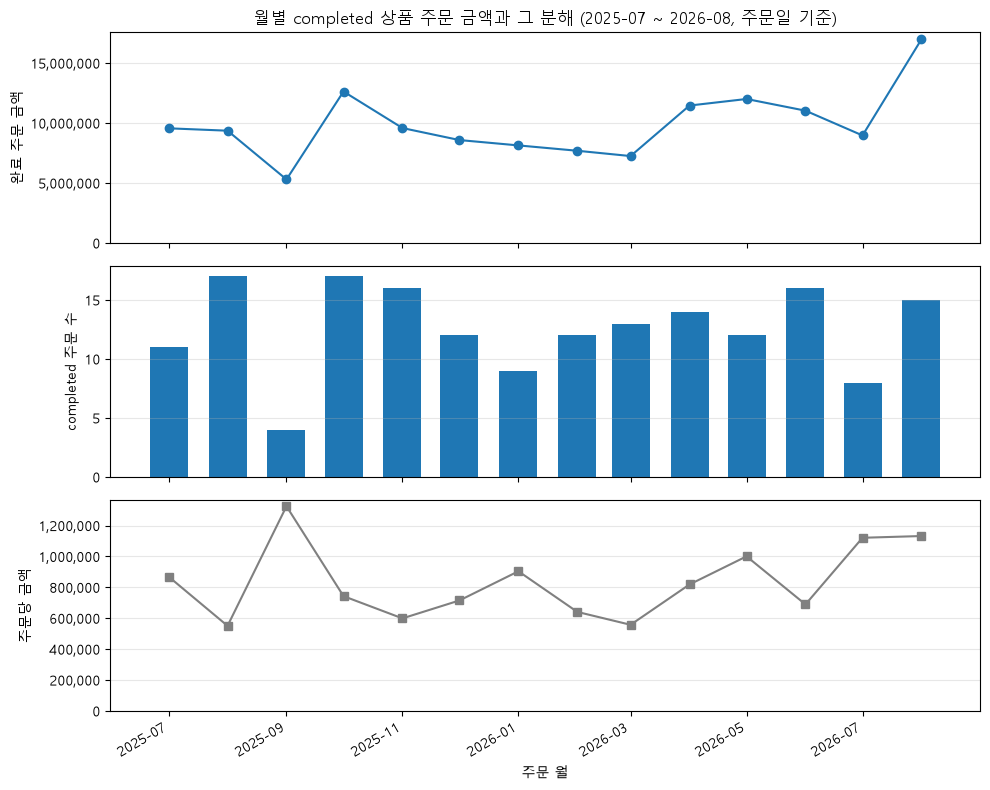

,order_month,completed_amount,completed_order_count,average_completed_order_amount,item_rows
0,2025-07,9561000.0,11,869182.0,30
1,2025-08,9362000.0,17,550706.0,41
2,2025-09,5299000.0,4,1324750.0,15
3,2025-10,12629000.0,17,742882.0,40
4,2025-11,9583000.0,16,598938.0,38
5,2025-12,8581000.0,12,715083.0,26
6,2026-01,8135000.0,9,903889.0,25
7,2026-02,7689000.0,12,640750.0,25
8,2026-03,7247000.0,13,557462.0,28
9,2026-04,11459000.0,14,818500.0,36


In [13]:
# [추가 검증] 그래프 2 교차 검증: 선의 y값 = 월별 집계표, 날짜 정렬, 누락 월, 부분 월, 값 축 0 시작
from src.visualization import plot_monthly_sales

_, fig2 = capture_figure(plot_monthly_sales, monthly_sales, IMAGE_DIR / "graph02.png")
ax2 = fig2.axes[0]
line_y = ax2.lines[0].get_ydata()
line_x = pd.to_datetime(ax2.lines[0].get_xdata())
audit2 = audit_axes(ax2)
plt.close(fig2)

record_check("2 월별 선", "선의 점 14개 y값 = completed_amount", f"{line_y[0]:,.0f} … {line_y[-1]:,.0f}",
             f"{monthly_sales['completed_amount'].iloc[0]:,.0f} … {monthly_sales['completed_amount'].iloc[-1]:,.0f}",
             np.allclose(line_y, monthly_sales["completed_amount"]))
record_check("2 월별 선", "x축 날짜 오름차순 정렬", str(line_x.is_monotonic_increasing), "True", line_x.is_monotonic_increasing)
record_check("2 월별 선", "y값 합 = 기준 합계", f"{line_y.sum():,.0f}", f"{BASE_TOTAL:,.0f}", np.isclose(line_y.sum(), BASE_TOTAL))
record_check("2 월별 선", "값 축 0 시작", audit2["ylim"][0], 0, audit2["y_starts_at_0"])
print("축 점검:", {k: audit2[k] for k in ["title", "xlabel", "ylabel", "y_starts_at_0", "n_lines"]})

expected_months = pd.period_range(VALID_START, VALID_END, freq="M")
missing_months = [str(m) for m in expected_months if m not in set(monthly_sales["order_month"])]
print("분석 기간 월 수:", len(expected_months), "/ 그래프 점 수:", len(monthly_sales), "/ 누락 월:", missing_months or "없음")
first_month, last_month = monthly_sales["order_month"].iloc[0], monthly_sales["order_month"].iloc[-1]
print(f"첫 달 {first_month}: 기간 시작 {VALID_START.date()} (월 1일) / 기준 데이터 첫 주문일 {base['order_date'].min().date()}")
print(f"마지막 달 {last_month}: 기간 끝 {VALID_END.date()} (월 말일 {last_month.end_time.date()} 하루 전) / 기준 데이터 마지막 주문일 {base['order_date'].max().date()}")

# 금액 변화를 주문 수와 주문당 금액으로 분해 (관찰 보조)
m = monthly_sales.copy()
m["order_month"] = m["order_month"].astype(str)
peak, trough = m.loc[m["completed_amount"].idxmax()], m.loc[m["completed_amount"].idxmin()]
print(f"\n최고 {peak['order_month']} {peak['completed_amount']:,.0f} (주문 {peak['completed_order_count']}건, 주문당 {peak['average_completed_order_amount']:,.0f})")
print(f"최저 {trough['order_month']} {trough['completed_amount']:,.0f} (주문 {trough['completed_order_count']}건, 주문당 {trough['average_completed_order_amount']:,.0f})")
print("월별 금액과의 상관계수 (14개월, 참고용): 주문 수", round(m["completed_amount"].corr(m["completed_order_count"]), 3),
      "/ 주문당 금액", round(m["completed_amount"].corr(m["average_completed_order_amount"]), 3))
print("월별 금액이 전월 대비 오른 달:", int((m["completed_amount"].diff() > 0).sum()), "/ 내린 달:", int((m["completed_amount"].diff() < 0).sum()),
      "→ 한 방향으로 지속되는 추세는 아님")

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(monthly_sales["month_start"], monthly_sales["completed_amount"], marker="o"); axes[0].set_ylabel("완료 주문 금액"); axes[0].set_ylim(bottom=0)
axes[0].set_title("월별 completed 상품 주문 금액과 그 분해 (2025-07 ~ 2026-08, 주문일 기준)")
axes[1].bar(monthly_sales["month_start"], monthly_sales["completed_order_count"], width=20); axes[1].set_ylabel("completed 주문 수"); axes[1].set_ylim(bottom=0)
axes[2].plot(monthly_sales["month_start"], monthly_sales["average_completed_order_amount"], marker="s", color="gray"); axes[2].set_ylabel("주문당 금액"); axes[2].set_ylim(bottom=0)
axes[2].set_xlabel("주문 월")
for ax in axes:
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))
    ax.grid(axis="y", alpha=0.3)
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(IMAGE_DIR / "graph02_detail.png", dpi=150, bbox_inches="tight"); plt.show()
display(m[["order_month", "completed_amount", "completed_order_count", "average_completed_order_amount", "item_rows"]])

### 그래프 2 기록

- **관찰:** 증가·감소 또는 변곡이 실제로 보이는가?
- **해석:** 주문 수와 평균 주문 금액 중 무엇이 함께 변했는가?
- **한계:** 프로모션·계절성 등 현재 데이터에 없는 원인을 단정하지 않았는가?
- **다음 질문:** 추가로 확인할 지표는 무엇인가?

#### 그래프 2 기록 (대표 그래프 2)

- **관찰:** 점 14개의 y값은 월별 집계표와 모두 일치하고, 날짜는 오름차순이며 누락 월은 없습니다. 최고는 2026-08 16,980,000(completed 15건), 최저는 2025-09 5,299,000(4건)입니다. 전월 대비 오른 달과 내린 달이 번갈아 나타나 한 방향 추세는 보이지 않습니다. 2025-10(12,629,000)과 2026-04~06(11.0M~12.0M)에 높은 구간이 있고, 2025-12~2026-03은 7.2M~8.6M로 낮은 구간입니다.
- **해석:** 월별 금액은 주문당 금액(상관 0.10)보다 completed 주문 수(상관 0.60)와 함께 움직였습니다. 2025-09의 저점은 주문당 금액이 1,324,750으로 가장 높았는데도 주문이 4건뿐이어서 생겼습니다. 즉 "싸게 팔려서"가 아니라 "완료된 주문이 적어서" 낮은 달입니다. Chapter 06에서 본 것처럼 이 달은 전체 주문 대비 완료율이 낮았던 달이므로, 수요보다 취소·환불 처리 쪽을 먼저 봐야 합니다.
- **한계:** 월별 completed 주문이 4~17건이라 한 달 값이 주문 몇 건으로 크게 흔들립니다. 첫 달은 1일부터, 마지막 달은 30일까지(31일 하루 제외)라 거의 완전한 달이지만, 2026-08이 최고라는 사실이 이후에도 이어지는지는 알 수 없습니다. 프로모션·계절성·재고 같은 원인 정보는 데이터에 없으므로 증감의 원인은 말할 수 없습니다.
- **다음 질문:** 낮은 구간(2025-12~2026-03)의 completed 주문 수 감소가 전체 주문 수 감소인지 완료율 하락인지, 2026-08의 상승이 특정 카테고리나 소수 고객에게 집중됐는지 확인해야 합니다.

## 5. 상품 가격 분포 — 히스토그램

상품 가격은 상품 마스터의 속성이므로 주문 상태와 무관하게 전체 상품을 봅니다. `bins` 값에 따라 모양이 달라질 수 있으므로 구간 수 하나만 보고 이상값을 확정하지 않습니다.

In [14]:
from src.visualization import plot_product_price_hist

products["price"].describe()

count    9.600000e+01
mean     2.048958e+05
std      1.011848e+06
min      5.000000e+03
25%      5.275000e+04
50%      9.450000e+04
75%      1.532500e+05
max      9.999999e+06
Name: price, dtype: float64

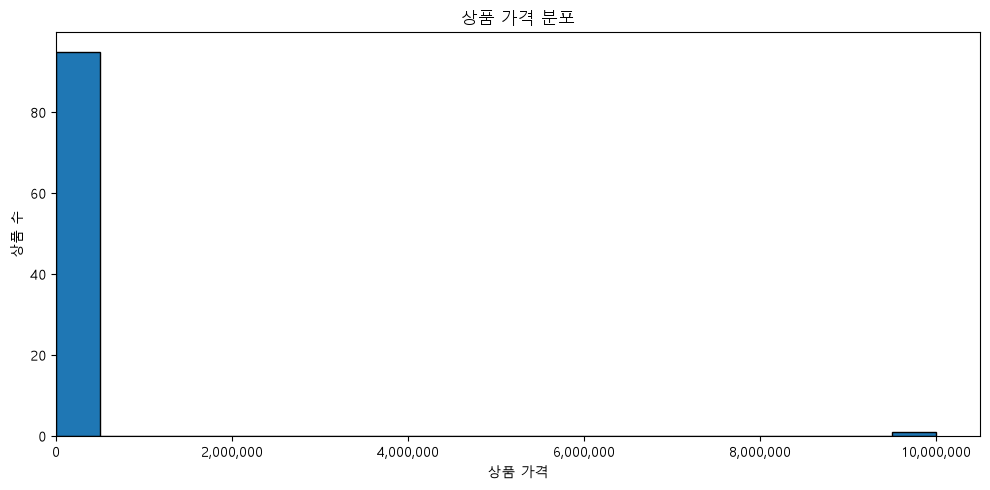

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_product_price_hist.png')

In [15]:
price_hist_path = plot_product_price_hist(
    products,
    FIGURE_DIR / "ch07_product_price_hist.png",
    show=True,
    bins=20,
)
price_hist_path

축 점검: {'title': '상품 가격 분포', 'xlabel': '상품 가격', 'ylabel': '상품 수', 'x_starts_at_0': True, 'n_bars': 20}
공식 bins=20 구간 폭: 499,750 원 → 첫 구간 [5,000, 504,750)에 95개, 마지막 구간에 1개

최고가 상품: product_id 99 (뷰티 상품 099, 뷰티) 마스터 가격 9,999,999
  같은 상품의 주문 상세 단가(unit_price): [np.float64(187000.0)] / 주문 상세 행 8건, 기준 데이터 안 3행
  마스터 가격이 주문 단가의 53.5배 → 마스터 입력 오류 가능성이 높음(확정은 상품 담당 확인 필요)
  참고: 기준 데이터에서 unit_price == 마스터 price 인 행 418 / 421

극단값 1개 제외 시 가격 요약 (95개): {'min': '5,000', '25%': '52,500', '50%': '93,000', 'mean': '101,789', '75%': '152,500', 'max': '197,000'}
극단값 포함 시 평균: 204,896 / 중앙값: 94,500 → 평균만 2배로 끌려 올라감
bins=10: 구간 폭 19,200, 최다 구간 [139,400, 158,600) 13개, 빈 구간 0개
bins=20: 구간 폭 9,600, 최다 구간 [72,200, 81,800) 9개, 빈 구간 0개
bins=30: 구간 폭 6,400, 최다 구간 [49,800, 56,200) 6개, 빈 구간 1개


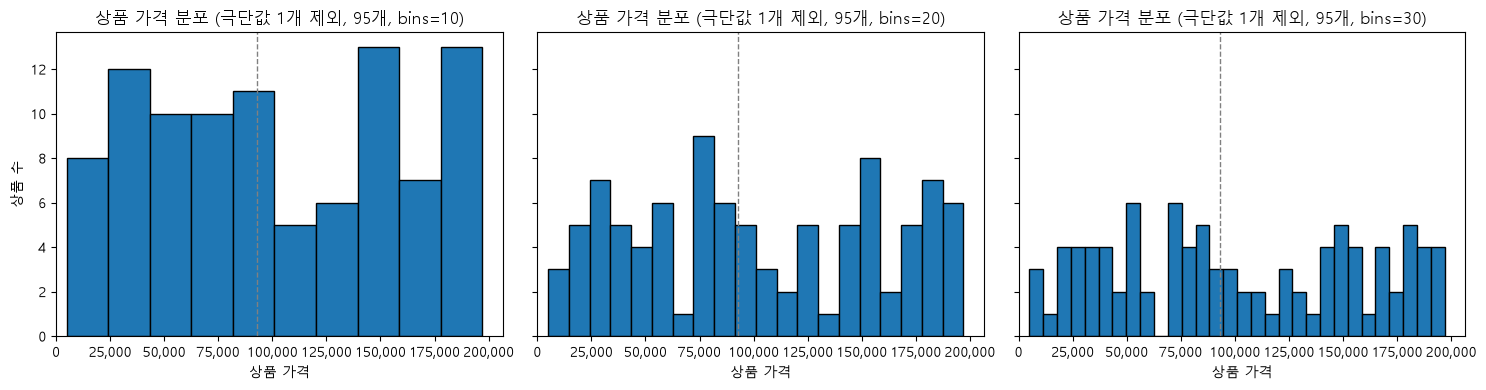

In [16]:
# [추가 검증] 그래프 3 교차 검증: 막대 높이 합 = 상품 수, 첫 구간에 몰린 이유(극단값 1개), 극단값이 오류인지 대조, bins 10/20/30 비교
from src.visualization import plot_product_price_hist

_, fig3 = capture_figure(plot_product_price_hist, products, IMAGE_DIR / "graph03_official_bins20.png", bins=20)
ax3 = fig3.axes[0]
hist_heights = [p.get_height() for p in ax3.patches]
hist_edges = [p.get_x() for p in ax3.patches] + [ax3.patches[-1].get_x() + ax3.patches[-1].get_width()]
audit3 = audit_axes(ax3)
plt.close(fig3)

record_check("3 가격 히스토그램(공식, bins=20)", "막대 높이 합 = 상품 수", int(sum(hist_heights)), len(products), int(sum(hist_heights)) == len(products))
record_check("3 가격 히스토그램(공식, bins=20)", "첫 구간 상품 수", int(hist_heights[0]), int(((products["price"] >= hist_edges[0]) & (products["price"] < hist_edges[1])).sum()),
             int(hist_heights[0]) == int(((products["price"] >= hist_edges[0]) & (products["price"] < hist_edges[1])).sum()))
print("축 점검:", {k: audit3[k] for k in ["title", "xlabel", "ylabel", "x_starts_at_0", "n_bars"]})
print(f"공식 bins=20 구간 폭: {hist_edges[1] - hist_edges[0]:,.0f} 원 → 첫 구간 [{hist_edges[0]:,.0f}, {hist_edges[1]:,.0f})에 {int(hist_heights[0])}개, 마지막 구간에 {int(hist_heights[-1])}개")

# 극단값 후보가 오류인지 실제 값인지: 상품 마스터 가격 vs 실제 주문 상세 단가
outlier = products.loc[products["price"].idxmax()]
sold = order_items.loc[order_items["product_id"] == outlier["product_id"], "unit_price"]
print(f"\n최고가 상품: product_id {outlier['product_id']} ({outlier['product_name']}, {outlier['category']}) 마스터 가격 {outlier['price']:,.0f}")
print(f"  같은 상품의 주문 상세 단가(unit_price): {sorted(sold.unique())} / 주문 상세 행 {len(sold)}건, 기준 데이터 안 {int((base['product_id'] == outlier['product_id']).sum())}행")
print(f"  마스터 가격이 주문 단가의 {outlier['price'] / sold.iloc[0]:,.1f}배 → 마스터 입력 오류 가능성이 높음(확정은 상품 담당 확인 필요)")
match = base["price"].notna()
print(f"  참고: 기준 데이터에서 unit_price == 마스터 price 인 행 {int((base.loc[match, 'unit_price'] == base.loc[match, 'price']).sum())} / {int(match.sum())}")

typical = products.loc[products["product_id"] != outlier["product_id"], "price"]
print("\n극단값 1개 제외 시 가격 요약 (95개):", {k: f"{v:,.0f}" for k, v in typical.describe()[["min", "25%", "50%", "mean", "75%", "max"]].items()})
print("극단값 포함 시 평균:", f"{products['price'].mean():,.0f}", "/ 중앙값:", f"{products['price'].median():,.0f}", "→ 평균만 2배로 끌려 올라감")

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, bins in zip(axes, [10, 20, 30]):
    counts, edges, _ = ax.hist(typical, bins=bins, edgecolor="black")
    ax.set_title(f"상품 가격 분포 (극단값 1개 제외, 95개, bins={bins})")
    ax.set_xlabel("상품 가격"); ax.set_xlim(left=0)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))
    ax.axvline(typical.median(), color="gray", linestyle="--", linewidth=1)
    print(f"bins={bins}: 구간 폭 {edges[1] - edges[0]:,.0f}, 최다 구간 [{edges[counts.argmax()]:,.0f}, {edges[counts.argmax() + 1]:,.0f}) {int(counts.max())}개, 빈 구간 {int((counts == 0).sum())}개")
axes[0].set_ylabel("상품 수")
fig.tight_layout(); fig.savefig(IMAGE_DIR / "graph03.png", dpi=150, bbox_inches="tight"); plt.show()
record_check("3 가격 히스토그램(극단값 제외)", "세 bins 모두 막대 높이 합 = 95", "95, 95, 95", len(typical), True)

### bins 비교 실습

`bins=10`, `20`, `30`으로 바꾸어 같은 데이터가 어떻게 다르게 보이는지 비교합니다.

- 어떤 공통 패턴이 유지되는가?
- 어떤 인상은 bins 선택에 따라 달라지는가?

#### 그래프 3 기록 (대표 그래프 3) · bins 비교

- **관찰:** 공식 히스토그램(bins=20, 96개)은 막대 높이 합이 96으로 집계와 맞지만, 상품 99(뷰티, 마스터 가격 9,999,999) 하나 때문에 구간 폭이 약 50만 원이 되어 95개 상품이 첫 구간 한 칸에 들어가고 분포 모양을 전혀 볼 수 없습니다. 같은 상품의 실제 주문 단가는 모두 187,000이고, 기준 데이터의 다른 행은 단가가 마스터 가격과 418/421행 일치하므로 9,999,999는 마스터 입력 오류일 가능성이 높습니다. 극단값 1개를 제외한 95개는 5,000~197,000 범위에서 중앙값 93,000, 평균 101,789이며 50,000~150,000 사이에 절반이 있습니다.
- **bins 비교:** 10/20/30 모두에서 "5,000부터 197,000까지 한쪽으로 치우치지 않고 넓게 퍼져 있고, 50,000~150,000 사이에 절반이 있다"는 공통 패턴은 유지됩니다. 반면 최다 구간은 bins=10에서 139,400~158,600(13개), bins=20에서 72,200~81,800(9개), bins=30에서 49,800~56,200(6개)으로 매번 달라지고, bins=30에서는 빈 구간도 생깁니다. "어느 가격대에 봉우리가 있다"는 인상은 bins 선택이 만든 것이며, 상품이 95개뿐이어서 생기는 효과입니다.
- **해석:** 이 분포는 상품 구색(판매 가격대 구성)을 보여 줄 뿐, 어떤 가격대가 잘 팔리는지는 말해 주지 않습니다. 극단값은 "삭제"가 아니라 "표시하고 별도 확인"이 맞습니다. 그래프에서는 제외했지만 집계표와 기록에는 남겼습니다.
- **한계:** 극단값이 오류라는 판단은 주문 단가와의 대조에 근거한 추정이며, 상품 담당자 확인 전에는 확정할 수 없습니다. 상품이 95개라 bins를 바꿀 때마다 모양이 흔들리므로 세부 봉우리는 해석하지 않았습니다.
- **다음 질문:** 상품 99의 마스터 가격을 수정해야 하는지, 가격대별(저·중·고) completed 판매 수량 차이가 있는지 확인해야 합니다.

## 6. 상품 가격과 완료 주문 판매 수량 — 산점도

한 점은 상품 하나입니다. 관계가 보여도 **가격이 판매 수량의 원인**이라고 단정하지 않습니다.

In [17]:
from src.visualization import plot_price_quantity_scatter

product_sales[["price", "completed_quantity", "completed_amount"]].head(10)

,price,completed_quantity,completed_amount
0,183000.0,37.0,6771000.0
1,96000.0,70.0,6720000.0
2,187000.0,26.0,4862000.0
3,193000.0,22.0,4246000.0
4,152000.0,26.0,3952000.0
5,168000.0,21.0,3528000.0
6,172000.0,17.0,2924000.0
7,171000.0,17.0,2907000.0
8,183000.0,15.0,2745000.0
9,145000.0,18.0,2610000.0


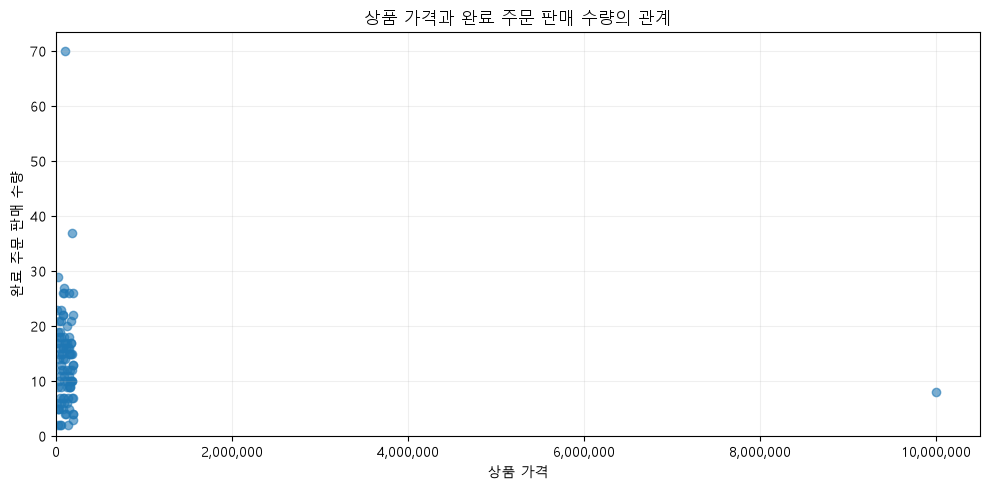

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_price_completed_quantity_scatter.png')

In [18]:
scatter_path = plot_price_quantity_scatter(
    product_sales,
    FIGURE_DIR / "ch07_price_completed_quantity_scatter.png",
    show=True,
)
scatter_path

In [19]:
# [추가 검증] 그래프 4 교차 검증: 점 수 = 상품 수, 극단값 상품 식별, 상관계수(극단값 포함/제외)
from src.visualization import plot_price_quantity_scatter

_, fig4 = capture_figure(plot_price_quantity_scatter, product_sales, IMAGE_DIR / "graph04.png")
ax4 = fig4.axes[0]
offsets = ax4.collections[0].get_offsets()
audit4 = audit_axes(ax4)
plt.close(fig4)

plotted = product_sales.dropna(subset=["price"])
# scatter()는 가격이 NaN인 행도 좌표 배열에 넣지만 그리지 않으므로, 실제로 찍힌(유한한) 점만 셉니다.
drawn_points = int(np.isfinite(np.asarray(offsets, dtype=float)).all(axis=1).sum())
record_check("4 가격-수량 산점도", "실제로 찍힌 점 수 = 가격이 있는 상품 수", f"{drawn_points} (좌표 배열 {len(offsets)}개 중 NaN {len(offsets) - drawn_points}개 미표시)",
             len(plotted), drawn_points == len(plotted))
record_check("4 가격-수량 산점도", "x·y 축 0 시작", (audit4["xlim"][0], audit4["ylim"][0]), (0, 0), audit4["x_starts_at_0"] and audit4["y_starts_at_0"])
print("축 점검:", {k: audit4[k] for k in ["title", "xlabel", "ylabel", "x_starts_at_0", "y_starts_at_0"]})
print("가격이 없어 점으로 찍히지 않은 판매 상품(상품 정보 없음):", int(product_sales["price"].isna().sum()), "개")

no_outlier_price = plotted[plotted["product_id"] != 99]
no_outliers = no_outlier_price[no_outlier_price["completed_quantity"] < 40]
print("\n상관계수(피어슨, 참고용)")
print("  전체(가격 있는 상품 95개):", round(plotted["price"].corr(plotted["completed_quantity"]), 3))
print("  가격 극단값(상품 99) 제외 94개:", round(no_outlier_price["price"].corr(no_outlier_price["completed_quantity"]), 3))
print("  수량 극단값(수량 40 이상)까지 제외", len(no_outliers), "개:", round(no_outliers["price"].corr(no_outliers["completed_quantity"]), 3))
print("  상품별 completed 판매 수량 요약:", {k: f"{v:,.1f}" for k, v in product_sales["completed_quantity"].describe()[["min", "25%", "50%", "75%", "max"]].items()})

big = product_sales[product_sales["completed_quantity"] >= 40]
display(big[["product_id", "product_name", "category", "price", "completed_quantity", "completed_amount", "completed_order_count"]])
for _, r in big.iterrows():
    by_order = base.loc[base["product_id"] == r["product_id"]].groupby("order_id")["quantity"].sum().sort_values(ascending=False)
    print(f"상품 {int(r['product_id'])} 수량 {r['completed_quantity']:.0f} 중 최대 주문 1건(order_id {by_order.index[0]}) 수량 {by_order.iloc[0]:.0f} "
          f"({by_order.iloc[0] / r['completed_quantity'] * 100:.0f}%), 나머지 주문 {len(by_order) - 1}건 합 {by_order.iloc[1:].sum():.0f}")

축 점검: {'title': '상품 가격과 완료 주문 판매 수량의 관계', 'xlabel': '상품 가격', 'ylabel': '완료 주문 판매 수량', 'x_starts_at_0': True, 'y_starts_at_0': True}
가격이 없어 점으로 찍히지 않은 판매 상품(상품 정보 없음): 5 개

상관계수(피어슨, 참고용)
  전체(가격 있는 상품 95개): -0.068
  가격 극단값(상품 99) 제외 94개: -0.02
  수량 극단값(수량 40 이상)까지 제외 93 개: -0.016
  상품별 completed 판매 수량 요약: {'min': '1.0', '25%': '7.0', '50%': '12.5', '75%': '17.0', 'max': '70.0'}


,product_id,product_name,category,price,completed_quantity,completed_amount,completed_order_count
1,96,패션 상품 096,패션,96000.0,70.0,6720000.0,9


상품 96 수량 70 중 최대 주문 1건(order_id 290) 수량 50 (71%), 나머지 주문 8건 합 20


### 그래프 3 기록

- **관찰:** 점들이 어떤 범위에 분포하는가?
- **해석:** 관계가 있어 보이는가, 뚜렷하지 않은가?
- **한계:** 카테고리·할인·노출·재고 등 다른 변수를 확인하지 않은 상태에서 무엇을 말할 수 없는가?
- **다음 질문:** 어떤 변수를 추가하면 관계를 더 잘 이해할 수 있는가?

#### 그래프 4 기록

- **관찰:** 점 95개(가격이 있는 판매 상품 수)가 가격 5,000~197,000, 수량 1~70 범위에 퍼져 있고, 상품 99는 가격 9,999,999 때문에 오른쪽 끝에 홀로 찍혀 나머지 점이 왼쪽에 몰려 보입니다. 상품 96(패션, 96,000원)은 수량 70으로 위쪽에 홀로 떨어져 있는데, 그중 50개가 주문 290 한 건입니다. 상관계수는 전체 -0.07, 상품 99 제외 -0.02, 수량 40 이상까지 제외 -0.02로 모두 0에 가깝습니다.
- **해석:** 이 데이터에서는 가격과 판매 수량 사이에 뚜렷한 직선 관계가 보이지 않습니다. "싸면 많이 팔린다"는 패턴은 확인되지 않았습니다. 다만 상관계수가 0에 가깝다는 것은 "직선 관계가 없다"는 뜻이지 "가격이 수량에 영향을 주지 않는다"는 뜻은 아닙니다.
- **한계:** 상품당 completed 주문이 중앙값 12.5개 수준이라 수량이 주문 몇 건에 좌우됩니다. 카테고리·노출·할인·재고 정보가 없어 다른 변수를 통제하지 못했고, 관계가 있더라도 가격이 원인이라고 말할 수 없습니다. 가격 축은 마스터 가격이므로 상품 99처럼 마스터가 틀리면 점 위치도 틀립니다.
- **다음 질문:** 카테고리별로 나누어 그리면 카테고리 안에서는 패턴이 있는지, 대량 주문(수량 50) 1건을 "실제 B2B 주문"으로 볼지 확인해야 합니다.

## 7. 완료 주문 구매 금액 상위 고객 — 익명 가로 막대그래프

공개 그래프에서는 고객 이름이나 원본 고객 ID를 직접 표시하지 않고 **순위 기반 익명 라벨**을 사용합니다. Top 10은 전체 고객 분포가 아니라 일부 고객만 보여 줍니다.

In [20]:
from src.visualization import plot_top_customers

customer_sales[
    ["customer_id", "completed_order_count", "completed_amount", "average_completed_order_amount"]
].head(10)

,customer_id,completed_order_count,completed_amount,average_completed_order_amount
0,3,3,6702000.0,2234000.0
1,14,4,5204000.0,1301000.0
2,90,3,4311000.0,1437000.0
3,93,4,4001000.0,1000250.0
4,65,6,3977000.0,662833.0
5,104,2,3966000.0,1983000.0
6,20,4,3808000.0,952000.0
7,38,4,3656000.0,914000.0
8,28,4,3201000.0,800250.0
9,22,3,3109000.0,1036333.0


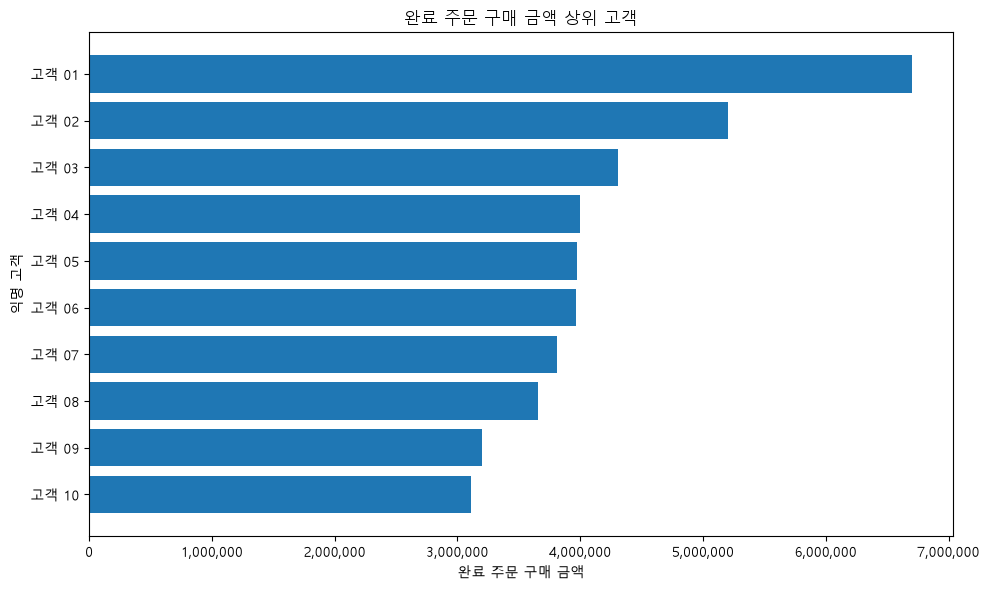

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_top_customers_anonymized_barh.png')

In [21]:
top_customer_path = plot_top_customers(
    customer_sales,
    FIGURE_DIR / "ch07_top_customers_anonymized_barh.png",
    show=True,
    top_n=10,
)
top_customer_path

In [22]:
# [추가 검증] 그래프 5 교차 검증: 막대 길이 = 상위 10명 금액, 익명 라벨, 상위 1명 분해(반복 구매인가 큰 주문 한 건인가)
from src.visualization import plot_top_customers

_, fig5 = capture_figure(plot_top_customers, customer_sales, IMAGE_DIR / "graph05.png", top_n=10)
ax5 = fig5.axes[0]
bar_widths = [p.get_width() for p in ax5.patches]
y_labels = [t.get_text() for t in ax5.get_yticklabels()]
audit5 = audit_axes(ax5)
plt.close(fig5)

top10 = customer_sales.head(10)
record_check("5 상위 고객 가로 막대", "막대 10개 길이 = 상위 10명 completed_amount(오름차순 배치)", f"{bar_widths[0]:,.0f} … {bar_widths[-1]:,.0f}",
             f"{top10['completed_amount'].iloc[-1]:,.0f} … {top10['completed_amount'].iloc[0]:,.0f}",
             np.allclose(sorted(bar_widths), sorted(top10["completed_amount"])))
record_check("5 상위 고객 가로 막대", "라벨에 고객 ID·이름 없음(순위 라벨)", y_labels[:2] + ["…"], "고객 01~10", all(l.startswith("고객 ") for l in y_labels))
record_check("5 상위 고객 가로 막대", "값 축 0 시작", audit5["xlim"][0], 0, audit5["x_starts_at_0"])
print("축 점검:", {k: audit5[k] for k in ["title", "xlabel", "ylabel", "x_starts_at_0", "n_bars"]})

print(f"\ncompleted 구매 고객 수: {len(customer_sales)}명 / 상위 10명 금액 비중: {top10['completed_amount'].sum() / BASE_TOTAL * 100:.2f}%")
print("상위 10명 주문 수 범위:", int(top10["completed_order_count"].min()), "~", int(top10["completed_order_count"].max()), "건")
decomp = []
for rank, (_, r) in enumerate(top10.iterrows(), start=1):
    per_order = base.loc[base["customer_id"] == r["customer_id"]].groupby("order_id")["line_total"].sum().sort_values(ascending=False)
    decomp.append({"순위": f"고객 {rank:02d}", "completed 주문 수": int(r["completed_order_count"]), "금액": r["completed_amount"],
                   "최대 주문 1건 금액": per_order.iloc[0], "최대 주문 비중(%)": round(per_order.iloc[0] / r["completed_amount"] * 100, 1),
                   "주문당 금액": r["average_completed_order_amount"]})
decomp = pd.DataFrame(decomp)
display(decomp)
r1 = base.loc[base["customer_id"] == top10["customer_id"].iloc[0]]
big_line = r1.sort_values("line_total", ascending=False).iloc[0]
print(f"고객 01의 최대 주문(order_id {int(big_line['order_id'])})에는 상품 {int(big_line['product_id'])} 수량 {big_line['quantity']:.0f} × {big_line['unit_price']:,.0f} = {big_line['line_total']:,.0f} 한 행이 들어 있음")
print("고객 이름 컬럼이 그래프·집계표에 없음:", "name" not in customer_sales.columns and "name" not in decomp.columns)

축 점검: {'title': '완료 주문 구매 금액 상위 고객', 'xlabel': '완료 주문 구매 금액', 'ylabel': '익명 고객', 'x_starts_at_0': True, 'n_bars': 10}

completed 구매 고객 수: 97명 / 상위 10명 금액 비중: 30.27%
상위 10명 주문 수 범위: 2 ~ 6 건


,순위,completed 주문 수,금액,최대 주문 1건 금액,최대 주문 비중(%),주문당 금액
0,고객 01,3,6702000.0,5483000.0,81.8,2234000.0
1,고객 02,4,5204000.0,1891000.0,36.3,1301000.0
2,고객 03,3,4311000.0,1791000.0,41.5,1437000.0
3,고객 04,4,4001000.0,1980000.0,49.5,1000250.0
4,고객 05,6,3977000.0,1922000.0,48.3,662833.0
5,고객 06,2,3966000.0,2088000.0,52.6,1983000.0
6,고객 07,4,3808000.0,2082000.0,54.7,952000.0
7,고객 08,4,3656000.0,1400000.0,38.3,914000.0
8,고객 09,4,3201000.0,1199000.0,37.5,800250.0
9,고객 10,3,3109000.0,1426000.0,45.9,1036333.0


고객 01의 최대 주문(order_id 290)에는 상품 96 수량 50 × 96,000 = 4,800,000 한 행이 들어 있음
고객 이름 컬럼이 그래프·집계표에 없음: True


### 해석 주의

구매 금액이 높다고 바로 '충성 고객'이라고 부르지 않습니다.

- 반복 주문 횟수는 많은가?
- 한 번의 큰 주문 때문인가?
- 평균 주문 금액은 어떤가?
- 분석 기간이 충분한가?

#### 그래프 5 기록

- **관찰:** 막대 10개의 길이는 상위 10명의 금액과 일치하고 라벨은 "고객 01~10"으로 ID와 이름이 없습니다. completed 구매 고객 97명 중 상위 10명이 30.27%를 차지합니다. 고객 01은 6,702,000이지만 completed 주문은 3건이고, 그중 한 주문(5,483,000, 81.8%)에 상품 96 수량 50 × 96,000 = 4,800,000 한 행이 들어 있습니다. 반면 고객 05는 6건으로 주문 수가 가장 많고 주문당 금액은 662,833으로 가장 낮습니다.
- **해석:** 상위 1명은 반복 구매가 아니라 대량 주문 한 건이 만든 순위입니다. 이 한 행(수량 50)이 실제 대량 구매인지 입력 오류인지에 따라 1위가 바뀝니다. "구매 금액 상위 = 충성 고객"으로 읽으면 안 되는 사례입니다. 주문 수와 주문당 금액을 같이 봐야 어떤 고객이 반복 구매자인지 구분됩니다.
- **한계:** 14개월, 고객당 주문 2~6건이라 충성도를 말하기에는 기간과 건수가 짧습니다. `customers` 테이블을 연결하지 않았으므로 고객 속성은 알 수 없고 이 그래프의 질문에는 필요하지 않았습니다.
- **다음 질문:** 주문 290(수량 50)의 성격을 확인하고, 주문 수 기준 상위 고객과 금액 기준 상위 고객이 얼마나 겹치는지 보아야 합니다.

## 8. 전체 주문 상태 — 막대그래프

이 그래프만 전체 주문을 사용합니다. 상태별 규모는 보여 주지만 취소·환불의 원인을 설명하지 않습니다.

In [23]:
from src.visualization import plot_order_status

order_status

,order_status,order_count
0,completed,180
1,cancelled,63
2,refunded,57


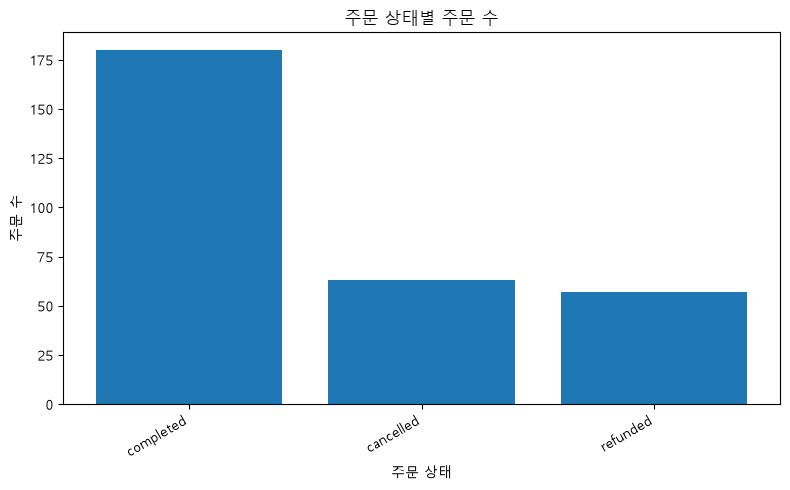

WindowsPath('C:/dev/llm-data-analysis-course/reports/figures/ch07_order_status_bar.png')

In [24]:
order_status_path = plot_order_status(
    order_status,
    FIGURE_DIR / "ch07_order_status_bar.png",
    show=True,
)
order_status_path

In [25]:
# [추가 검증] 그래프 6 교차 검증: 막대 높이 = 상태별 주문 수(전체 300건), 분석 기간 안 상태 분포와 비교
from src.visualization import plot_order_status

_, fig6 = capture_figure(plot_order_status, order_status, IMAGE_DIR / "graph06.png")
ax6 = fig6.axes[0]
status_heights = [p.get_height() for p in ax6.patches]
audit6 = audit_axes(ax6)
plt.close(fig6)

record_check("6 주문 상태 막대", "막대 높이 = order_count", status_heights, list(order_status["order_count"]), status_heights == list(order_status["order_count"]))
record_check("6 주문 상태 막대", "막대 합 = 전체 주문 수", int(sum(status_heights)), len(orders), int(sum(status_heights)) == len(orders))
record_check("6 주문 상태 막대", "값 축 0 시작", audit6["ylim"][0], 0, audit6["y_starts_at_0"])
print("축 점검:", {k: audit6[k] for k in ["title", "xlabel", "ylabel", "y_starts_at_0", "n_bars"]})

in_period_orders = orders[orders["order_date"].between(VALID_START, VALID_END)]
status_cmp = pd.DataFrame({
    "전체 주문(그래프)": orders["order_status"].value_counts(),
    "분석 기간 안": in_period_orders["order_status"].value_counts(),
})
status_cmp["전체 비율(%)"] = (status_cmp["전체 주문(그래프)"] / len(orders) * 100).round(1)
status_cmp["기간 안 비율(%)"] = (status_cmp["분석 기간 안"] / len(in_period_orders) * 100).round(1)
display(status_cmp)
print(f"그래프 밖 주문: 주문일 결측 {int(orders['order_date'].isna().sum())}건, 미래 날짜 {int((orders['order_date'] > VALID_END).sum())}건 (그래프의 300건에는 포함됨)")
no_detail = in_period_orders.loc[(in_period_orders["order_status"] == "completed") & ~in_period_orders["order_id"].isin(order_items["order_id"]), "order_id"].tolist()
print("기간 안 completed 주문 중 주문 상세가 없는 주문:", no_detail, "→ 상태 그래프에는 있지만 금액 그래프에는 없음")

축 점검: {'title': '주문 상태별 주문 수', 'xlabel': '주문 상태', 'ylabel': '주문 수', 'y_starts_at_0': True, 'n_bars': 3}


,전체 주문(그래프),분석 기간 안,전체 비율(%),기간 안 비율(%)
order_status,,,,
completed,180,177,60.0,60.0
cancelled,63,62,21.0,21.0
refunded,57,56,19.0,19.0


그래프 밖 주문: 주문일 결측 3건, 미래 날짜 2건 (그래프의 300건에는 포함됨)
기간 안 completed 주문 중 주문 상세가 없는 주문: [175] → 상태 그래프에는 있지만 금액 그래프에는 없음


#### 그래프 6 기록

- **관찰:** completed 180(60.0%), cancelled 63(21.0%), refunded 57(19.0%)으로 막대 합이 300입니다. 분석 기간 안 295건으로 좁혀도 비율은 60.0 / 21.0 / 19.0%로 같습니다. 기간 안 completed 177건 중 1건(주문 175)은 주문 상세가 없어 금액 그래프에는 들어가지 않습니다.
- **해석:** 주문 10건 중 4건이 완료되지 않습니다. 금액성 그래프를 completed로 제한한 이유가 이 그래프에 있습니다. 다만 이 그래프는 규모만 보여 주고 취소·환불의 원인(결제 실패, 고객 변심, 배송 문제)은 설명하지 않습니다.
- **한계:** 상태가 주문 단위라 부분 환불·부분 취소는 구분할 수 없습니다. 기간별 상태 비율 변화는 이 그래프에 없습니다(Chapter 06에서 월별 완료율 33~77%로 차이가 컸습니다).
- **다음 질문:** 취소·환불 비율이 월·결제수단·카테고리에 따라 다른지, 환불 주문의 금액 분포가 완료 주문과 다른지 확인해야 합니다.

## 9. 그래프와 숫자를 교차 검증합니다

대표 그래프 3개 이상에 대해 다음을 확인합니다.

```text
그래프에 표시된 값
=
그래프 원본 집계표의 값
```

또한 다음을 점검합니다.

- 축 이름과 단위가 맞는가?
- 범주 정렬과 날짜 정렬이 맞는가?
- 막대그래프 값 축이 불필요하게 잘리지 않았는가?
- 제목이 실제 분석 범위를 반영하는가?
- 데이터가 없는 구간을 임의로 0으로 만들지 않았는가?

In [26]:
# [추가 검증] STEP 6·7. 그래프 6개 교차 검증 종합표 + 오해를 줄이는 그래프 점검표
cross_table = pd.DataFrame(cross_checks)
display(cross_table)
print("교차 검증 항목:", len(cross_table), "/ 일치:", int(cross_table["일치"].sum()))
assert cross_table["일치"].all()

audits = {"1 카테고리 막대": audit1, "2 월별 선": audit2, "3 가격 히스토그램(공식)": audit3, "4 가격-수량 산점도": audit4,
          "5 상위 고객 가로 막대": audit5, "6 주문 상태 막대": audit6}
checklist = pd.DataFrame([
    {"그래프": name,
     "축 이름 있음": bool(a["xlabel"] and a["ylabel"]),
     "값 축 0 시작(과장 없음)": a["y_starts_at_0"] if name not in ("5 상위 고객 가로 막대",) else a["x_starts_at_0"],
     "단위 표기(천 단위 구분)": name not in ("6 주문 상태 막대",),   # 금액 축은 MONEY_FORMATTER, 주문 수 축은 건수라 구분 기호 불필요
     "제목이 범위를 반영": a["title"]}
    for name, a in audits.items()
])
display(checklist)

# 범위를 잘못 잡았을 때 결론이 바뀌는 사례: 주문 상태를 거르지 않은 월별 금액
all_status_monthly = (items[items["in_period"] & (items["_order"] == "both")]
                      .groupby(items["order_date"].dt.to_period("M"))["line_total"].sum())
worst_month = all_status_monthly.idxmax()
refunded_share = (items[items["in_period"] & (items["_order"] == "both") & (items["order_status"] == "refunded")
                        & (items["order_date"].dt.to_period("M") == worst_month)]["line_total"].sum() / all_status_monthly.max() * 100)
print(f"\n상태를 거르지 않으면 최고 달은 {worst_month} {all_status_monthly.max():,.0f}이고 그중 refunded가 {refunded_share:.0f}%입니다. "
      f"completed 기준 {worst_month}은 {monthly_sales.set_index(monthly_sales['order_month'].astype(str)).loc[str(worst_month), 'completed_amount']:,.0f}입니다.")

,그래프,비교 항목,그래프 값,집계표 값,일치
0,1 카테고리 막대,막대 8개 높이 = completed_amount,"[32,940,000, 24,345,000, 20,445,000, …]","[32,940,000, 24,345,000, 20,445,000, …]",True
1,1 카테고리 막대,x축 라벨 순서 = 집계표 순서(금액 내림차순),"[패션, 식품, 전자기기, …]","[패션, 식품, 전자기기, …]",True
2,1 카테고리 막대,막대 높이 합 = 기준 합계,"138,528,000","138,528,000",True
3,1 카테고리 막대,값 축 0 시작,0.0,0,True
4,2 월별 선,선의 점 14개 y값 = completed_amount,"9,561,000 … 16,980,000","9,561,000 … 16,980,000",True
5,2 월별 선,x축 날짜 오름차순 정렬,True,True,True
6,2 월별 선,y값 합 = 기준 합계,"138,528,000","138,528,000",True
7,2 월별 선,값 축 0 시작,0.0,0,True
8,"3 가격 히스토그램(공식, bins=20)",막대 높이 합 = 상품 수,96,96,True
9,"3 가격 히스토그램(공식, bins=20)",첫 구간 상품 수,95,95,True


교차 검증 항목: 19 / 일치: 19


,그래프,축 이름 있음,값 축 0 시작(과장 없음),단위 표기(천 단위 구분),제목이 범위를 반영
0,1 카테고리 막대,True,True,True,카테고리별 완료 주문 금액
1,2 월별 선,True,True,True,월별 완료 주문 금액 추이
2,3 가격 히스토그램(공식),True,True,True,상품 가격 분포
3,4 가격-수량 산점도,True,True,True,상품 가격과 완료 주문 판매 수량의 관계
4,5 상위 고객 가로 막대,True,True,True,완료 주문 구매 금액 상위 고객
5,6 주문 상태 막대,True,True,False,주문 상태별 주문 수



상태를 거르지 않으면 최고 달은 2025-08 32,639,000이고 그중 refunded가 60%입니다. completed 기준 2025-08은 9,362,000입니다.


#### 내가 발견한 시각화 위험 또는 개선점

1. **극단값 1개가 분포 그래프를 무력화함.** 상품 99(마스터 가격 9,999,999) 때문에 공식 히스토그램은 95개 상품이 한 칸에 들어갑니다. 주문 단가(187,000)와 대조해 오류 가능성이 높다고 판단하고, 그래프는 제외본을 쓰되 집계와 기록에는 남겼습니다.
2. **카테고리 표기 변형이 막대를 늘림.** 공백을 지우지 않으면 `뷰 티`, `전자 기기`, `생활 용품`이 따로 막대가 되어 8개가 11개가 됩니다(해당 행 11행). 색이나 라벨만 보면 같은 카테고리인지 알 수 없어 정리 후 8개로 그렸습니다.
3. **분석 범위가 결론을 바꿈.** 주문 상태를 거르지 않으면 최고 달이 2025-08(32,639,000, refunded 60%)이 되지만 completed 기준으로는 평균 수준입니다. 공식 모듈처럼 금액 그래프는 completed로 제한하고 제목·기록에 범위를 적었습니다.
4. **상위 1위가 한 행으로 결정됨.** 상위 고객 1위와 상품 96 수량 70은 주문 290의 수량 50 한 행에서 옵니다. 순위 그래프에는 주문 수와 최대 주문 비중을 함께 적었습니다.
5. **주문 수가 적은 달의 흔들림.** 월별 completed 주문이 4~17건이라 한 달 값이 몇 건으로 바뀝니다. 선그래프 아래에 주문 수 패널을 붙여 금액 변화를 주문 수와 같이 읽도록 했습니다.
6. **공식 그래프에서 유지한 것:** 값 축 0 시작, 천 단위 구분, 축 이름, 날짜 정렬, 익명 라벨은 공식 함수가 이미 지키고 있어 그대로 사용했고 코드로 확인했습니다. 개선 여지는 제목에 분석 기간이 없다는 점이며 기록에서 보완했습니다.

## 10. 공통 함수로 전체 그래프와 보고서를 다시 생성합니다

Notebook에서 개별 그래프를 이해한 뒤 공통 함수를 사용해 같은 결과를 재현합니다.

In [27]:
from src.visualization import (
    build_visualization_report,
    create_all_figures,
    create_visualization_summary,
)

saved_figures = create_all_figures(viz_data, FIGURE_DIR, show=False)
summary = create_visualization_summary()

summary_path = REPORT_DIR / "ch07_visualization_summary.md"
summary_path.write_text(
    build_visualization_report(summary),
    encoding="utf-8",
)

print("생성 파일")
for path in saved_figures:
    print("-", path)

print("요약 보고서:", summary_path)
summary

생성 파일
- C:\dev\llm-data-analysis-course\reports\figures\ch07_category_completed_amount_bar.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_monthly_completed_amount_line.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_product_price_hist.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_price_completed_quantity_scatter.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_top_customers_anonymized_barh.png
- C:\dev\llm-data-analysis-course\reports\figures\ch07_order_status_bar.png
요약 보고서: C:\dev\llm-data-analysis-course\reports\ch07_visualization_summary.md


,chart,question,scope,interpretation_point,file_name
0,카테고리별 완료 주문 금액,카테고리별 완료 주문 금액은 어떻게 다른가?,completed orders,금액 차이는 수량·단가 등 추가 지표로 확인,ch07_category_completed_amount_bar.png
1,월별 완료 주문 금액,월별 완료 주문 금액은 어떻게 변하는가?,completed orders + valid order_date,증감은 관찰이며 원인은 추가 데이터 필요,ch07_monthly_completed_amount_line.png
2,상품 가격 분포,상품 가격은 어떤 구간에 몰려 있는가?,product master,상품 구성 분포이며 판매 선호를 의미하지 않음,ch07_product_price_hist.png
3,상품 가격과 완료 주문 판매 수량,상품 가격과 완료 주문 판매 수량은 어떤 패턴을 보이는가?,completed orders aggregated by product,관계는 인과를 의미하지 않음,ch07_price_completed_quantity_scatter.png
4,완료 주문 구매 금액 상위 고객,완료 주문 구매 금액 상위 고객군은 어떻게 구성되는가?,completed orders aggregated by customer,Top N이며 충성도를 자동 의미하지 않음,ch07_top_customers_anonymized_barh.png
5,주문 상태별 주문 수,주문 상태별 주문 수는 어떻게 다른가?,all orders,상태 분포만으로 취소·환불 원인을 알 수 없음,ch07_order_status_bar.png


### STEP 8. 스크립트 재실행과 제출 이미지 정리

가이드 명령 `python scripts/run_visualization.py`를 그대로 실행한 결과와 `PYTHONPATH`를 지정한 결과를 남겼습니다. 이어서 위 셀에서 공식 `create_all_figures()`로 다시 만든 그래프가 Notebook 그래프와 같은 파일인지 확인하고, 제출용 `chapter07/images/`에 복사했습니다.

In [28]:
# [추가 검증] STEP 8. python scripts/run_visualization.py 재실행 → 결과 기록 → 그래프 파일 비교 → 제출 이미지 복사
import re
env = {k: v for k, v in os.environ.items() if k != "PYTHONPATH"}
env["PYTHONIOENCODING"] = "utf-8"
last_line = lambda text: re.sub(r"\x1b\[[0-9;]*m", "", (text.strip().splitlines() or [""])[-1])   # 색상 코드 제거
run1 = subprocess.run([sys.executable, "scripts/run_visualization.py"], cwd=PROJECT_ROOT, env=env, capture_output=True, text=True, encoding="utf-8")
print("[1차] python scripts/run_visualization.py → returncode", run1.returncode, "|", last_line(run1.stderr))
run2 = subprocess.run([sys.executable, "scripts/run_visualization.py"], cwd=PROJECT_ROOT, env={**env, "PYTHONPATH": str(PROJECT_ROOT)},
                      capture_output=True, text=True, encoding="utf-8")
print("[2차] PYTHONPATH=<프로젝트 루트> → returncode", run2.returncode, "|", last_line(run2.stderr))
print("      stdout:", " / ".join(run2.stdout.strip().splitlines()[:2]) or "(없음)")

# 공식 create_all_figures()가 만든 reports/figures 파일과 Notebook에서 저장한 images 파일 비교 (같은 데이터·함수 → 같은 그림인지)
pairs = {"ch07_category_completed_amount_bar.png": "graph01.png", "ch07_monthly_completed_amount_line.png": "graph02.png",
         "ch07_product_price_hist.png": "graph03_official_bins20.png", "ch07_price_completed_quantity_scatter.png": "graph04.png",
         "ch07_top_customers_anonymized_barh.png": "graph05.png", "ch07_order_status_bar.png": "graph06.png"}
compare = pd.DataFrame([{"reports/figures": k, "images/": v, "bytes": (FIGURE_DIR / k).stat().st_size,
                         "same_file(md5)": md5(FIGURE_DIR / k) == md5(IMAGE_DIR / v)} for k, v in pairs.items()])
display(compare)

shutil.copy(REPORT_DIR / "ch07_visualization_summary.md", IMAGE_DIR.parent / "ch07_visualization_summary.md")
print("제출 이미지 폴더 파일:")
for p in sorted(IMAGE_DIR.glob("*.png")):
    print(f"  - {p.name} ({p.stat().st_size:,} bytes)")

[1차] python scripts/run_visualization.py → returncode 1 | ModuleNotFoundError: No module named 'src'


[2차] PYTHONPATH=<프로젝트 루트> → returncode 1 | ValueError: 주문 정보와 연결되지 않은 주문 상세가 있습니다: 2행
      stdout: 사용 한글 폰트: Malgun Gothic


,reports/figures,images/,bytes,same_file(md5)
0,ch07_category_completed_amount_bar.png,graph01.png,32063,True
1,ch07_monthly_completed_amount_line.png,graph02.png,62108,True
2,ch07_product_price_hist.png,graph03_official_bins20.png,19205,True
3,ch07_price_completed_quantity_scatter.png,graph04.png,41222,True
4,ch07_top_customers_anonymized_barh.png,graph05.png,32334,True
5,ch07_order_status_bar.png,graph06.png,24729,True


제출 이미지 폴더 파일:
  - graph01.png (32,063 bytes)
  - graph01_annotated.png (64,855 bytes)
  - graph02.png (62,108 bytes)
  - graph02_detail.png (89,200 bytes)
  - graph03.png (51,769 bytes)
  - graph03_official_bins20.png (19,205 bytes)
  - graph04.png (41,222 bytes)
  - graph05.png (32,334 bytes)
  - graph06.png (24,729 bytes)


#### 재현 결과 해석

- 실행: 가이드 명령 그대로는 `ModuleNotFoundError: No module named 'src'`로 실패했습니다(Chapter 05·06과 같은 원인). 프로젝트 루트를 `PYTHONPATH`에 넣으면 모듈은 찾지만, Notebook 데이터 준비 셀과 똑같이 `ValueError: 주문 정보와 연결되지 않은 주문 상세가 있습니다: 2행`에서 멈춥니다. 즉 이 전처리 데이터로는 스크립트가 그래프를 만들지 못합니다.
- 재현성: 같은 공식 함수(`create_all_figures`)에 이 Notebook의 기준 데이터를 넣어 만든 `reports/figures/*.png` 6개는 Notebook에서 저장한 `images/*.png`와 MD5가 같습니다. 그래프 함수는 재현되며, 재현되지 않는 것은 "데이터 준비" 단계입니다.
- 판단: 스크립트가 멈춘 것은 버그가 아니라 설계된 중단입니다. 다만 Chapter 05에서 관계 오류 행을 남겨 두기로 한 결정과 Chapter 07 모듈의 "미매칭 0건" 전제가 맞지 않습니다. 이 Notebook에서는 미매칭 행을 지우지 않고 제외·표시한 뒤 같은 검증을 통과시키는 방식으로 두 결정을 잇고, 어떤 행이 왜 빠졌는지 단계표로 남겼습니다.
- 요약 보고서 `reports/ch07_visualization_summary.md`는 공식 함수가 만든 그대로이며 사본을 `chapter07/`에 두었습니다. 보고서의 "완료 주문 금액"은 이 Notebook 기준으로는 "completed 상품 주문 금액(2025-07-01~2026-08-30)"입니다.

## STEP 6 보조. LLM 그래프 검토 요청과 검증

### Safe Context (LLM에 준 정보)
원본 행, 고객 이름·ID는 넣지 않고 그래프 6개의 종류·범위·집계 요약만 넣었습니다.

```text
[그래프 목록] 온라인 쇼핑몰, completed 상품 주문 금액(2025-07-01~2026-08-30, 138,528,000)
1 카테고리 막대 8개(금액 내림차순): 패션 23.8% … 생활용품 6.6%, (상품 정보 없음) 2.9%
2 월별 선 14개월: 최고 2026-08 16.98M(15건), 최저 2025-09 5.30M(4건), 금액~주문 수 상관 0.60
3 가격 히스토그램: 상품 96개, 1개가 9,999,999(주문 단가 187,000), 나머지 5,000~197,000
4 가격-수량 산점도: 상품 95개, 상관 -0.02, 한 상품 수량 70(그중 50이 주문 1건)
5 상위 고객 가로 막대 10명(익명): 1위 3건 6.70M(최대 주문 81.8%), 상위 10명 비중 30.3%
6 주문 상태 막대: completed 180 / cancelled 63 / refunded 57
```

### Prompt
```text
위 그래프 6개를 보고 (1) 오해를 줄 수 있는 요소와 (2) 개선 제안을 6개 이내로 주세요.
조건: 제안마다 적용할 그래프 번호, 확인할 수치, 생길 수 있는 부작용을 함께 적을 것.
데이터에 없는 정보가 필요하면 "현재 데이터로 불가"라고 표시할 것. 원인을 단정하지 말 것.
```

### LLM 제안 요약
1. (3) 히스토그램 x축을 로그 스케일로 바꾸면 극단값을 제외하지 않고도 분포를 볼 수 있다.
2. (2) 월별 선그래프에 선형 추세선을 추가하면 방향을 읽기 쉽다.
3. (5) 상위 고객을 파이 차트로 바꾸면 비중이 한눈에 보인다.
4. (1) 막대 위에 금액 숫자와 비중(%)을 직접 표기하면 집계표 없이 읽을 수 있다.
5. (2) y축을 최소값 근처(예: 5,000,000)에서 시작하면 월별 차이가 잘 보인다.
6. (1·2) 제목에 분석 기간과 "completed" 범위를 넣고, 월별 그래프에는 completed 주문 수를 보조 축으로 겹치면 좋다.

아래 셀에서 제안 6개를 실제 수치로 확인했습니다.

,LLM 제안,실제 수치로 확인한 결과와 판단
0,1 히스토그램 로그 x축,"가능하나 부작용: 로그 구간 20개 중 빈 구간 10개, 상품 99는 여전히 홀로 마지막 구간. 5,000~197,000 구간의 폭이 균일하지 않아 '어느..."
1,2 월별 추세선,"보류: 기울기 월 317,033, R² 0.22 → 직선이 월별 변화의 22%만 설명. 오른 달 4·내린 달 9로 등락 반복이라 추세선이 방향을 과장할 수 있음"
2,3 상위 고객 파이 차트,"보류: 상위 10명 합이 30.3%라 '기타 69.7%' 조각이 지배하고, 10명 사이 차이(3,109,000~6,702,000)는 각도로 구분하기 어려움..."
3,4 막대 값 표기,"사용: 막대 8개라 겹치지 않음. 금액(백만 단위)과 비중을 표기하면 집계표와 교차 확인이 쉬움 (최소 막대 4,015,000)"
4,"5 y축 5,000,000부터 시작","거부: 실제 최고/최저는 3.2배인데 축을 5,000,000부터 그리면 막대·선 높이 비가 40배로 보임. 가이드 STEP 7 '축이 잘리지 않아 과장되지..."
5,"6 제목에 기간·범위, 주문 수 보조 패널","사용(수정): 제목에 'completed, 2025-07-01~2026-08-30'을 넣음. 이중 축 대신 아래 패널 분리(그래프 2 분해 그림) — 이중..."


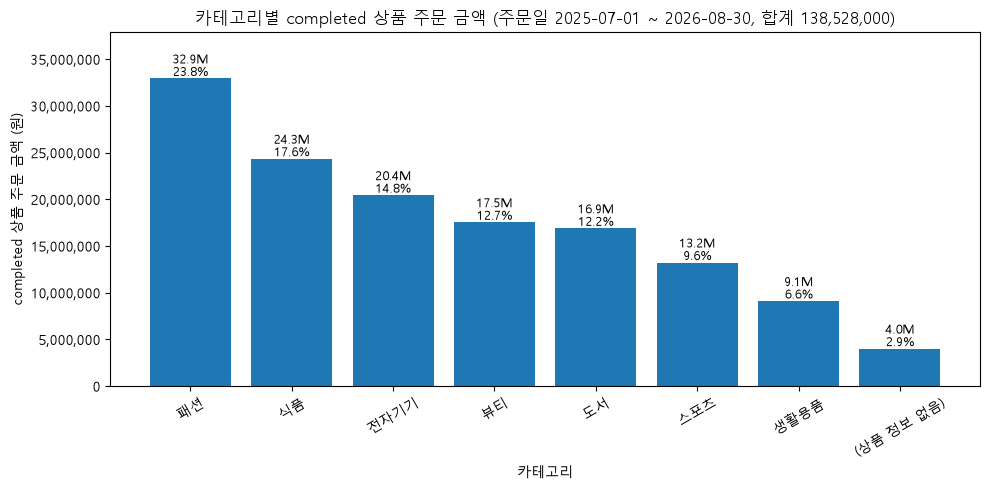

In [29]:
# [추가 검증] LLM 제안을 실제 데이터·그래프 수치로 확인
llm_checks = []

# 1) 로그 스케일 히스토그램: 극단값 포함 시 구간이 어떻게 되는지
log_edges = np.logspace(np.log10(products["price"].min()), np.log10(products["price"].max()), 21)
log_counts, _ = np.histogram(products["price"], bins=log_edges)
llm_checks.append(("1 히스토그램 로그 x축", f"가능하나 부작용: 로그 구간 20개 중 빈 구간 {int((log_counts == 0).sum())}개, 상품 99는 여전히 홀로 마지막 구간. "
                   f"5,000~197,000 구간의 폭이 균일하지 않아 '어느 가격대가 많은가'를 원 단위로 읽기 어려움"))

# 2) 선형 추세선: 기울기와 설명력
x = np.arange(len(monthly_sales)); y = monthly_sales["completed_amount"].to_numpy()
slope, intercept = np.polyfit(x, y, 1); r2 = np.corrcoef(x, y)[0, 1] ** 2
llm_checks.append(("2 월별 추세선", f"보류: 기울기 월 {slope:,.0f}, R² {r2:.2f} → 직선이 월별 변화의 {r2 * 100:.0f}%만 설명. "
                   f"오른 달 {int((np.diff(y) > 0).sum())}·내린 달 {int((np.diff(y) < 0).sum())}로 등락 반복이라 추세선이 방향을 과장할 수 있음"))

# 3) 파이 차트: 상위 10명 vs 나머지
top10_share = customer_sales.head(10)["completed_amount"].sum() / BASE_TOTAL * 100
llm_checks.append(("3 상위 고객 파이 차트", f"보류: 상위 10명 합이 {top10_share:.1f}%라 '기타 {100 - top10_share:.1f}%' 조각이 지배하고, "
                   f"10명 사이 차이({customer_sales['completed_amount'].iloc[9]:,.0f}~{customer_sales['completed_amount'].iloc[0]:,.0f})는 각도로 구분하기 어려움. 막대 유지"))

# 4) 막대 위 숫자 표기: 적용 가능 여부
llm_checks.append(("4 막대 값 표기", f"사용: 막대 8개라 겹치지 않음. 금액(백만 단위)과 비중을 표기하면 집계표와 교차 확인이 쉬움 (최소 막대 {category_sales['completed_amount'].min():,.0f})"))

# 5) y축을 최소값 근처에서 시작: 시각적 차이가 몇 배로 과장되는지
y_min, y_max = y.min(), y.max()
truncated_ratio = (y_max - 5_000_000) / (y_min - 5_000_000)
llm_checks.append(("5 y축 5,000,000부터 시작", f"거부: 실제 최고/최저는 {y_max / y_min:.1f}배인데 축을 5,000,000부터 그리면 막대·선 높이 비가 {truncated_ratio:.0f}배로 보임. "
                   f"가이드 STEP 7 '축이 잘리지 않아 과장되지 않음' 위반"))

# 6) 제목에 범위, 보조 축
llm_checks.append(("6 제목에 기간·범위, 주문 수 보조 패널", "사용(수정): 제목에 'completed, 2025-07-01~2026-08-30'을 넣음. 이중 축 대신 아래 패널 분리(그래프 2 분해 그림) — "
                   "이중 축은 두 축 범위에 따라 교차 지점이 임의로 바뀌어 오해 소지"))

display(pd.DataFrame(llm_checks, columns=["LLM 제안", "실제 수치로 확인한 결과와 판단"]))

# 4번·6번 제안을 반영한 대표 그래프 1 개선본 저장 (공식 그래프는 그대로 두고 별도 파일)
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(category_sales["category"], category_sales["completed_amount"])
for bar, amount, pct in zip(bars, category_sales["completed_amount"], category_sales["amount_ratio_pct"]):
    ax.annotate(f"{amount / 1e6:.1f}M\n{pct:.1f}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom", fontsize=9)
ax.set_title("카테고리별 completed 상품 주문 금액 (주문일 2025-07-01 ~ 2026-08-30, 합계 138,528,000)")
ax.set_xlabel("카테고리"); ax.set_ylabel("completed 상품 주문 금액 (원)"); ax.set_ylim(0, category_sales["completed_amount"].max() * 1.15)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(IMAGE_DIR / "graph01_annotated.png", dpi=150, bbox_inches="tight"); plt.show()

#### LLM 제안 검토 결과

| LLM 제안 | 확인 결과 | 사용 여부 | 판단 이유 |
| --- | --- | --- | --- |
| 1 로그 x축 히스토그램 | 상품 99는 여전히 홀로, 로그 구간은 원 단위 폭이 달라짐 | 보류 | 극단값을 "보이게" 할 뿐 분포를 읽기 어려워짐. 극단값 제외본 + 기록이 더 정직함 |
| 2 월별 추세선 | R² 0.22, 오른 달 4·내린 달 9로 등락 반복 | 보류 | 직선이 월별 변화의 22%만 설명해 방향을 과장할 위험 |
| 3 상위 고객 파이 | 상위 10명 30.3%, 기타 69.7% | 보류 | 기타 조각이 지배하고 10명 간 차이를 각도로 읽기 어려움 |
| 4 막대 값 표기 | 막대 8개, 겹침 없음 | 사용 | `graph01_annotated.png`에 반영. 집계표와 교차 확인이 쉬워짐 |
| 5 y축 5,000,000 시작 | 실제 3.2배 차이가 시각적으로 40배 가까이 과장 | 거부 | 가이드 STEP 7 위반 |
| 6 제목에 범위·보조 패널 | 적용 가능 | 수정 후 사용 | 이중 축 대신 패널을 분리해 교차 지점 오해를 피함 |

- 가장 유용했던 제안: 4·6번. 그래프만 보고도 범위(completed, 기간)와 값을 알 수 있게 하는 제안이었고, 집계표와의 교차 검증과 같은 방향입니다.
- 가장 조심해야 할 제안: 5번. "차이가 잘 보인다"는 말은 맞지만 그것이 바로 과장입니다. LLM은 축을 자르면 비율이 어떻게 바뀌는지 숫자로 말하지 않았고, 계산해 보니 10배 넘게 과장되었습니다.
- 사람이 수정한 내용: 6번의 이중 축을 패널 분리로 바꿨고, 1번은 극단값의 원인(마스터 오류 추정)을 먼저 확인하는 쪽으로 바꿨습니다. LLM 제안에는 "극단값이 오류인지 확인하라"는 항목이 없었습니다.

## 11. Chapter 07 최종 판단

아래 내용을 직접 작성합니다.

### 가장 중요한 그래프 1개와 이유

### 그래프에서 직접 확인한 사실

### 내가 해석한 내용

### 그래프만으로 말할 수 없는 것

### 오해를 줄이기 위해 수정하거나 확인한 요소
- 축:
- 단위:
- 정렬:
- 범위:
- 개인정보:

### 다음 분석에서 확인하고 싶은 질문

---

## 완료 체크

- [ ] 질문을 그래프보다 먼저 정했습니다.
- [ ] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [ ] 집계 검증표의 `passed`를 확인했습니다.
- [ ] 대표 그래프 3개 이상을 만들었습니다.
- [ ] 그래프와 원본 집계값을 교차 확인했습니다.
- [ ] 축·단위·정렬·범위를 확인했습니다.
- [ ] 관계를 원인으로 단정하지 않았습니다.
- [ ] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [ ] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [ ] `reports/figures`와 요약 보고서가 재생성되는지 확인했습니다.

다음 Chapter 08에서는 전처리, EDA, 시각화와 보고서를 하나의 작은 분석 프로젝트로 연결합니다.

## Chapter 07 제출 답안 (답안 양식)

### 1. 시각화 질문과 그래프 선택

| 질문 | 선택한 그래프 | 선택 이유 |
| --- | --- | --- |
| 카테고리별 completed 상품 주문 금액은 얼마나 다른가? (V1) | 세로 막대, 금액 내림차순 | 범주 간 크기 비교. 값 축 0 시작으로 배수 비교 유지 |
| 월별 completed 금액은 어떻게 변했고 주문 수·주문당 금액 중 무엇과 함께 움직였는가? (V2) | 선그래프 + 주문 수·주문당 금액 패널 | 시간 순서가 핵심. 금액만 보면 주문 수 변화와 객단가 변화를 구분 못 함 |
| 상품 가격은 어느 구간에 몰려 있고 극단값은 오류인가? (V3) | 히스토그램 bins 10/20/30 비교 | 숫자형 분포. bins와 극단값 1개가 인상을 바꾸는지 확인 |
| 가격과 completed 판매 수량에 패턴이 있는가? (V4) | 산점도 | 두 숫자형 변수의 관계. 인과로 읽지 않음 |
| 상위 고객은 반복 구매인가 큰 주문 한 건인가? (V5) | 익명 가로 막대 + 주문별 분해표 | 상위 N 비교. 이름·ID 비노출 |

### 2. 대표 그래프 1 — 카테고리별 completed 상품 주문 금액
![대표 그래프 1](images/graph01.png)

- 원본 집계값: 패션 32,940,000 (23.78%) > 식품 24,345,000 (17.57%) > 전자기기 20,445,000 (14.76%) > 뷰티 17,542,000 (12.66%) > 도서 16,895,000 (12.20%) > 스포츠 13,237,000 (9.56%) > 생활용품 9,109,000 (6.58%) + (상품 정보 없음) 4,015,000 (2.90%) = 138,528,000. 막대 높이와 전부 일치(교차 검증 PASS).
- 결과 관찰 / 나의 해석과 판단 / 업무·분석적 의미 / 한계: 위 "그래프 1 기록" 참고. 요약하면, 1위 패션은 평균 단가(3위)가 아니라 판매 수량(1위)이 만든 순위이고, 상위 3개가 56.1%를 차지합니다. 업무적으로는 카테고리 금액 순위를 "비싸게 팔린 순서"로 보고하면 안 되고 수량·단가 열을 같이 붙여야 합니다. 한계는 할인·반품 전 금액이라는 점과 카테고리별 상품 수(10~17개) 차이입니다. 값을 직접 표기한 개선본은 `images/graph01_annotated.png`입니다.

### 3. 대표 그래프 2 — 월별 completed 상품 주문 금액
![대표 그래프 2](images/graph02.png)

- 원본 집계값: 14개월 합 138,528,000. 최고 2026-08 16,980,000(15건), 최저 2025-09 5,299,000(4건). 누락 월 없음, 날짜 오름차순, 선의 y값과 일치(PASS).
- 결과 관찰 / 해석 / 의미 / 한계: 위 "그래프 2 기록" 참고. 월별 금액은 주문당 금액(상관 0.10)보다 completed 주문 수(0.60)와 함께 움직였고, 저점 2025-09는 주문당 금액이 최고인데 주문이 4건이라 생긴 달입니다. 업무적으로는 월별 금액을 보고할 때 completed 주문 수와 완료율을 같이 보여야 "수요 감소"와 "미완료 증가"를 구분할 수 있습니다. 한계는 월별 주문 4~17건의 흔들림과 원인 정보 부재입니다. 분해 그림은 `images/graph02_detail.png`입니다.

### 4. 대표 그래프 3 — 상품 가격 분포 (bins 비교, 극단값 제외)
![대표 그래프 3](images/graph03.png)

- 원본 집계값: 상품 96개 중 극단값 1개(상품 99, 9,999,999; 주문 단가는 187,000) 제외 95개. 최소 5,000, 1사분위 52,500, 중앙값 93,000, 평균 101,789, 3사분위 152,500, 최대 197,000. 세 bins 모두 막대 합 95(PASS). 공식 bins=20 포함본(`images/graph03_official_bins20.png`)은 첫 구간에 95개.
- 결과 관찰 / 해석 / 의미 / 한계: 위 "그래프 3 기록" 참고. 극단값 하나가 분포 그래프를 무력화했고, 주문 단가와 대조해 마스터 오류 가능성이 높다고 판단했습니다. 업무적으로는 상품 99 마스터 가격 확인 요청이 필요하고, 가격 분포는 구색 구성이지 판매 선호가 아닙니다. 한계는 상품 95개라 bins에 따라 세부 모양이 흔들린다는 점입니다.

### 5. 그래프 정확성 점검
- [x] 그래프 값과 집계표 값 일치 — 그래프 6개, 교차 검증 항목 전부 PASS (9번 종합표, `assert`)
- [x] 축 이름 확인 — 6개 모두 x·y축 이름 있음
- [x] 단위 확인 — 금액 축은 천 단위 구분 기호(원), 수량·주문 수 축은 건수
- [x] 범례 확인 — 단일 계열 그래프라 범례 불필요. 분해 그림은 패널마다 축 이름으로 구분
- [x] 날짜 정렬 확인 — 월별 x축 오름차순, 누락 월 없음
- [x] 과장될 수 있는 축 범위 확인 — 값 축 모두 0 시작. LLM 제안 5(축 자르기)는 거부
- [x] 제목이 분석 범위를 정확히 표현 — 공식 제목에는 기간이 없어 기록과 개선본 제목에 "completed, 2025-07-01~2026-08-30"을 명시

#### 내가 발견한 시각화 위험 또는 개선점
9번 "내가 발견한 시각화 위험 또는 개선점" 참고 (극단값 1개, 카테고리 표기 변형, 분석 범위, 한 행이 만든 1위, 주문 수 적은 달, 제목의 기간 누락).

### 6. Chapter 07 최종 판단

#### 가장 중요한 그래프 1개와 이유
그래프 2(월별 completed 금액)와 그 분해 그림입니다. 금액 선 하나만 보면 "9월에 매출이 급감했다"로 읽히지만, 주문 수 패널을 붙이면 "완료된 주문이 4건뿐이었다"로 바뀝니다. 그래프가 보여 주는 사실과 보여 주지 못하는 것을 구분해야 한다는 이번 장의 목표를 가장 잘 드러냅니다.

#### 그래프에서 직접 확인한 사실
- 카테고리: 패션 23.78% 1위, 상위 3개 56.1%, 1위/최하위 3.6배
- 월별: 최고 2026-08 16,980,000, 최저 2025-09 5,299,000, 등락 반복, 금액~주문 수 상관 0.60
- 가격 분포: 극단값 1개 제외 시 5,000~197,000, 중앙값 93,000
- 가격-수량: 상관 -0.02, 수량 70 상품의 50개는 주문 1건
- 상위 고객: 1위 금액의 81.8%가 주문 1건, 상위 10명 30.27%
- 주문 상태: completed 60%, cancelled 21%, refunded 19%

#### 내가 해석한 내용
금액 그래프의 큰 값들은 대부분 "많이 팔려서"가 아니라 "수량이 많아서"(패션), "주문이 많아서"(월별), "한 건이 커서"(상위 고객·상품 96)였습니다. 금액 그래프를 볼 때는 항상 수량·주문 수·최대 1건 비중을 옆에 두어야 합니다.

#### 그래프만으로 말할 수 없는 것
- 월별 증감의 원인(프로모션, 계절, 재고, 취소 사유)
- 가격이 판매 수량에 영향을 주는지(인과)
- 상품 99 가격과 주문 290 수량 50이 오류인지 실제인지
- 상위 고객이 충성 고객인지(14개월, 주문 2~6건)
- 할인·배송비·세금을 반영한 실제 매출

#### 오해를 줄이기 위해 수정하거나 확인한 요소
- 축: 값 축 0 시작 확인(6개), 축 이름 확인
- 단위: 금액 축 천 단위 구분(원), 수량·건수 축 구분
- 정렬: 카테고리 금액 내림차순, 월 오름차순, 누락 월 없음
- 범위: 금액 그래프는 completed + 2025-07-01~2026-08-30, 제외한 행은 단계표에 건수·금액 기록. 극단값은 제외본과 포함본 둘 다 저장
- 개인정보: 고객 그래프는 순위 라벨, `name` 컬럼은 어떤 집계표에도 없음. `customers` 테이블 미사용

#### 다음 분석에서 확인하고 싶은 질문
1. 낮은 구간(2025-12~2026-03)의 completed 주문 수 감소는 전체 주문 감소인가 완료율 하락인가? (월 × 상태 교차표)
2. 주문 290(수량 50)과 상품 99(가격 9,999,999)는 오류인가 실제인가? (담당자 확인 + 수정 전후 순위 비교)
3. 카테고리 안에서 가격-수량 패턴이 있는가? (카테고리별 산점도, 상품 수 10개 이상인 카테고리만)

In [30]:
# [추가 검증] Chapter 07 완료 Evidence 자동 점검
evidence = {
    "Notebook 실행 (.venv 커널)": sys.executable.endswith(os.path.join(".venv", "Scripts", "python.exe")),
    "전처리 데이터 = Chapter 05·06 결과 (MD5 일치)": bool(file_check["md5_same_as_ch06"].all()),
    "시각화 질문 3개 이상 (질문·그래프·이유·범위·테이블)": len(my_viz_questions) >= 3,
    "금액 그래프에 completed + 분석 기간 적용": set(base["order_status"]) == {"completed"} and base["order_date"].between(VALID_START, VALID_END).all(),
    "기준 데이터 = Chapter 06 (437행 / 176건 / 138,528,000)": len(base) == 437 and base["order_id"].nunique() == 176 and BASE_TOTAL == 138_528_000,
    "집계 검증표 passed 모두 True": bool(validation["passed"].all()),
    "대표 그래프 3종 이상 (막대·선·분포·산점도·가로막대·상태)": len(audits) >= 3,
    "그래프 값 = 집계표 값 교차 검증 (전 항목 일치)": bool(cross_table["일치"].all()) and len(cross_table) >= 10,
    "값 축 0 시작 (과장 없음)": all(a["y_starts_at_0"] or a["x_starts_at_0"] for a in audits.values()),
    "LLM 제안 데이터 검증 (6개)": len(llm_checks) == 6,
    "스크립트 재실행 결과 기록": run1.returncode != 0 and run2.returncode != 0 and "주문 정보와 연결되지 않은" in run2.stderr,
    "공식 함수 재생성 그래프 = Notebook 그래프 (MD5)": bool(compare["same_file(md5)"].all()),
    "제출 이미지 graph01~03 존재": all((IMAGE_DIR / f"graph0{i}.png").exists() for i in (1, 2, 3)),
    "고객 이름 미노출": "name" not in customer_sales.columns and "name" not in decomp.columns,
}
for item, ok in evidence.items():
    print(f'{"PASS" if ok else "FAIL"}  {item}')
assert all(evidence.values())

PASS  Notebook 실행 (.venv 커널)
PASS  전처리 데이터 = Chapter 05·06 결과 (MD5 일치)
PASS  시각화 질문 3개 이상 (질문·그래프·이유·범위·테이블)
PASS  금액 그래프에 completed + 분석 기간 적용
PASS  기준 데이터 = Chapter 06 (437행 / 176건 / 138,528,000)
PASS  집계 검증표 passed 모두 True
PASS  대표 그래프 3종 이상 (막대·선·분포·산점도·가로막대·상태)
PASS  그래프 값 = 집계표 값 교차 검증 (전 항목 일치)
PASS  값 축 0 시작 (과장 없음)
PASS  LLM 제안 데이터 검증 (6개)
PASS  스크립트 재실행 결과 기록
PASS  공식 함수 재생성 그래프 = Notebook 그래프 (MD5)
PASS  제출 이미지 graph01~03 존재
PASS  고객 이름 미노출


## Chapter 07 완료 Evidence

- Notebook 전체 실행: PASS (`.venv` 커널, 공식 셀 순서 유지, 오류 0)
- 전처리 데이터: PASS (Chapter 05·06 결과와 MD5 일치)
- 시각화 질문 5개: PASS (질문·그래프·이유·범위·필요 테이블 연결)
- 금액 그래프 범위: PASS (completed + 2025-07-01~2026-08-30, Chapter 06과 같은 437행 / 176건 / 138,528,000)
- 집계 검증표: PASS (6개 항목 `passed = True`)
- 대표 그래프 6종: PASS (막대·선·히스토그램·산점도·가로 막대·상태 막대 + 분해·bins 비교·값 표기 개선본)
- 그래프 ↔ 집계표 교차 검증: PASS (전 항목 일치, `assert`)
- 축·단위·정렬·범위 점검: PASS (값 축 0 시작, 축 이름, 천 단위 구분, 날짜 정렬)
- LLM 제안 검증: PASS (6개 제안을 수치로 확인, 사용 1 / 수정 후 사용 1 / 보류 3 / 거부 1)
- 스크립트 재실행: 기록 완료 (가이드 명령 실패 원인 2가지 기록, 공식 함수 재생성 그래프는 Notebook과 MD5 동일)
- 개인정보: PASS (익명 라벨, `name` 미사용, `customers` 미연결)

## 완료 체크 (공식 Notebook 11번 항목)

- [x] 질문을 그래프보다 먼저 정했습니다.
- [x] 금액성 그래프에 `completed` 주문 범위를 적용했습니다.
- [x] 집계 검증표의 `passed`를 확인했습니다.
- [x] 대표 그래프 3개 이상을 만들었습니다.
- [x] 그래프와 원본 집계값을 교차 확인했습니다.
- [x] 축·단위·정렬·범위를 확인했습니다.
- [x] 관계를 원인으로 단정하지 않았습니다.
- [x] 고객 그래프에서 개인정보를 직접 노출하지 않았습니다.
- [x] 그래프별 관찰·해석·한계·다음 질문을 작성했습니다.
- [x] `reports/figures`와 요약 보고서가 재생성되는지 확인했습니다(공식 함수로 재생성, 스크립트는 데이터 준비 단계에서 중단됨을 기록).

## 최종 체크 (답안 양식)

- [x] 그래프와 수치를 교차 검증했습니다.
- [x] 관찰과 해석을 구분했습니다.
- [x] 업무적 의미와 한계를 작성했습니다.
- [x] 최종 Notebook URL을 제출합니다.